![Logo Javeriana](https://images.seeklogo.com/logo-png/11/1/pontificia-universidad-javeriana-logo-png_seeklogo-110703.png)

# Nombre: Gabriel Jaramillo Cuberos (Id: 20529022)

Materia: Procesamiento de Datos (1255)

Tema: PySpark con ML para modelos de Derrame Cerebral en Pacientes

Fecha: 19 de noviembre de 2026

Objetivos: 
- Aplicar la metodología CRISP-DM en datasets de las ciencias de la salud
- Documentar de forma exhaustiva cada actividad realizada de la metodología
- Crear y analizar gráficas: comprender la creación de gráficas como imágenes que documenten de forma académica
- Hacer las recomendaciones, conclusiones, análisis correspondientes
- Hacer uso del entorno IDE Python cuaderno: servidor personal
- Usar un dataset de Accidentes Cerebro Vaculares
- Hacer análisis y conclusiones

Nombre del fichero: 1255JaramilloStroke.ipynb

## Contexto y alcance del taller

Este cuaderno desarrolla un análisis de registros con características demográficas, antecedentes y mediciones de salud, junto con la etiqueta `stroke`, renombrada como `Derrame`.

El trabajo comprende conocimiento de los datos, preparación, exploración, entrenamiento de cinco modelos de MLlib y evaluación sobre un conjunto separado de prueba.

El objetivo es comparar la clasificación de la etiqueta disponible y comprender cómo la calidad de los datos, las transformaciones y el desbalance de clases influyen en la interpretación de los resultados.

La metodología sigue las fases de comprensión del problema, comprensión de los datos, preparación, modelado, evaluación y comunicación de resultados de CRISP-DM.

Las conclusiones se limitan a la muestra y al experimento realizado. El cuaderno no demuestra causalidad, predicción de eventos futuros ni validación clínica.

**Nota:** Instalación de seaborn en el entorno spark.

In [1]:
%pip install seaborn

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


# Comprobar entorno y kernel
#import sys
#import os
#import pyspark
#from pyspark import SparkConf

#print("Python:", sys.version)
#print("Ejecutable:", sys.executable)
#print("PySpark:", pyspark.__version__)
print("Ubicación de PySpark:", pyspark.__file__)
print("SPARK_HOME:", os.environ.get("SPARK_HOME"))
print("SPARK_CONF_DIR:", os.environ.get("SPARK_CONF_DIR"))

In [2]:
#Generic Libraries
import numpy as np                  # linear algebra
import pandas as pd                 # data processing, CSV file I/O (e.g. pd.read_csv)
import matplotlib as mtplib
import seaborn as sns               # Creación de gráficas y biblioteca estadística
import matplotlib.pyplot as plt     # Implementación de gráfica

import findspark
findspark.init("/mnt/sda1/Cluster/Spark/")

#Apache Spark Libraries
from pyspark import SparkConf, SparkContext                    # SparkConf:       // SparkContext:
from pyspark.sql import SparkSession, SQLContext

from pyspark.sql import functions as F                           # Se importan todas las funciones: when, column, ...
from pyspark.sql.types import *

#Apache Spark ML CLassifier Libraries
from pyspark.ml.classification import DecisionTreeClassifier,RandomForestClassifier,NaiveBayes

#Apache Spark Evaluation Library
from pyspark.ml.evaluation import MulticlassClassificationEvaluator

#Apache Spark Features libraries
from pyspark.ml.feature import StandardScaler,StringIndexer, VectorAssembler, VectorIndexer, OneHotEncoder

#Apache Spark Pipelin Library
from pyspark.ml import Pipeline

# Apache Spark `DenseVector`
from pyspark.ml.linalg import DenseVector

#Data Split Libraries
import sklearn
from sklearn.model_selection import train_test_split

from datetime import date

#Tabulating Data
#from tabulate import tabulate

#Garbage
import gc

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

In [3]:
# Se crea una configuración para la sesión SPARK

#Configuración del clúster del profesor John Corredor
configura = SparkConf().set("spark.ui.port","37010") # Configuración del puerto
configura.setAppName("DerrameBigData_Jaramillo")

sparkJaramillo = SparkSession.builder.config(conf = configura).getOrCreate()
SQLContext(sparkContext = sparkJaramillo.sparkContext, sparkSession = sparkJaramillo)

sparkContextJaramillo = sparkJaramillo.sparkContext.getOrCreate()

print("Sesión creada el", date.today())
sparkJaramillo

#Configuración del clúster del grupo
#sparkJaramillo = (
#    SparkSession.builder
#    .appName("DerrameBigData_Jaramillo")
#    .master("spark://10.43.97.76:8888")
#    .config("spark.pyspark.python", "/usr/bin/python3.11")
#    .config(
#        "spark.scheduler.allocation.file",
#        "file:///opt/cluster/spark/conf/fairscheduler.xml"
#    )
#    .config("spark.executor.memory", "1g")
#    .config("spark.executor.cores", "2")
#    .config("spark.cores.max", "2")
#    .getOrCreate()
#)

#SQLContext(
#    sparkContext = sparkJaramillo.sparkContext,
#    sparkSession = sparkJaramillo
#)

## Se levanta el contexto para la sesión: Aplicación de Derrame Cerebral en SPARK
#sparkContextJaramillo = sparkJaramillo.sparkContext.getOrCreate()

## Se imprime para verificar
#print("Sesión creada el", date.today())
#sparkJaramillo

Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


Sesión creada el 2026-11-19


## Carga de dataset

Se carga el dataset usando la ruta del archivo de derrames cerebrales. Este archivo se encuentra en el clúster del equipo.

In [4]:
!/mnt/sda1/Cluster/Hadoop/bin/hadoop fs -ls /csv

Found 11 items
drwxr-xr-x   - sistemas supergroup          0 2026-10-23 13:39 /csv/BankMarketing
-rw-r--r--   2 sistemas supergroup     977501 2026-03-10 15:27 /csv/CustomerChurn.csv
-rw-r--r--   2 sistemas supergroup      40868 2025-07-07 15:41 /csv/Fortune500USCompanies.csv
drwxr-xr-x   - sistemas supergroup          0 2025-10-16 14:17 /csv/auxiliar
drwxr-xr-x   - sistemas supergroup          0 2026-11-12 12:16 /csv/calidadAgua
-rw-r--r--   2 sistemas supergroup      34635 2025-09-02 13:22 /csv/jugadores.csv
-rw-r--r--   2 sistemas supergroup    1082023 2025-09-02 13:22 /csv/resultados_futbol.csv
-rw-r--r--   2 sistemas supergroup     316971 2025-06-10 09:11 /csv/stroke_pyspark.csv
drwxr-xr-x   - sistemas supergroup          0 2025-06-18 15:36 /csv/taxi
drwxr-xr-x   - sistemas supergroup          0 2026-04-23 15:56 /csv/titanic
-rw-r--r--   2 sistemas supergroup      84199 2026-04-23 17:11 /csv/winequality-red.csv


Revisar contenido de la carpeta de taxi.

In [5]:
!/mnt/sda1/Cluster/Hadoop/bin/hadoop fs -ls /csv/taxi

Found 3 items
-rw-r--r--   2 sistemas supergroup      89594 2025-06-18 15:19 /csv/taxi/taxi-etl-input-small.csv
-rw-r--r--   2 sistemas supergroup     278795 2025-06-18 15:26 /csv/taxi/taxi-test.csv
-rw-r--r--   2 sistemas supergroup    1114146 2025-06-18 15:26 /csv/taxi/taxi-train.csv


Revisar contenido de la carpeta titanic.

In [6]:
!/mnt/sda1/Cluster/Hadoop/bin/hadoop fs -ls /csv/titanic

Found 3 items
-rw-r--r--   2 sistemas supergroup      28629 2026-04-23 15:56 /csv/titanic/test.csv
-rw-r--r--   2 sistemas supergroup      88432 2026-04-23 15:48 /csv/titanic/titanic_com.csv
-rw-r--r--   2 sistemas supergroup      61194 2026-04-23 15:56 /csv/titanic/train.csv


In [7]:
# Url del archivo del clúster del profesor
url = "hdfs://10.195.34.34:9000/csv/stroke_pyspark.csv"

df00 = sparkJaramillo.read.format("csv") \
        .option("header", "true") \
        .option("inferSchema", "true")\
        .load(url) # Establecer ruta del archivo

df00.show(5)

+-----+------+----+------------+-------------+------------+-------------+--------------+-----------------+----+---------------+------+
|   id|gender| age|hypertension|heart_disease|ever_married|    work_type|Residence_type|avg_glucose_level| bmi| smoking_status|stroke|
+-----+------+----+------------+-------------+------------+-------------+--------------+-----------------+----+---------------+------+
| 9046|  Male|67.0|           0|            1|         Yes|      Private|         Urban|           228.69|36.6|formerly smoked|     1|
|51676|Female|61.0|           0|            0|         Yes|Self-employed|         Rural|           202.21| N/A|   never smoked|     1|
|31112|  Male|80.0|           0|            1|         Yes|      Private|         Rural|           105.92|32.5|   never smoked|     1|
|60182|Female|49.0|           0|            0|         Yes|      Private|         Urban|           171.23|34.4|         smokes|     1|
| 1665|Female|79.0|           1|            0|         

### Diccionario de variables y unidad de análisis

Cada fila es un registro de una persona según la estructura del archivo. Antes de asumir que son personas distintas, debe comprobarse la unicidad de `id` y la ausencia de duplicados. El archivo parte de **5.110 registros**, según la suma de las categorías originales de género; después del filtro de `Other` quedan **5.109**.

| Columna original → nombre usado | Tipo conceptual | Interpretación y precaución |
|---|---|---|
| `id` → `id` | Identificador | Sirve para trazabilidad y duplicados; no mide una característica del paciente. |
| `gender` → `Genero` | Categórica nominal | Contiene `Female`, `Male` y originalmente un `Other`. Conservar la definición del archivo sin atribuirle información biológica adicional no documentada. |
| `age` → `Edad` | Cuantitativa | Se recibe como decimal; el código la convierte a entero y pierde la fracción de año. |
| `hypertension` → `Hipertension` | Categórica binaria | Indicador codificado 0/1. No es una medición continua de presión arterial. |
| `heart_disease` → `EnfCardiaca` | Categórica binaria | Indicador 0/1; no identifica aquí una patología cardiaca específica ni su gravedad. |
| `ever_married` → `EdoCivil` | Categórica binaria | El nombre original se refiere a **haber estado casado alguna vez**, no al estado civil actual ni a todas sus categorías posibles. |
| `work_type` → `TipoTrabajo` | Categórica nominal | `Private`, `Self-employed`, `Govt_job`, `children`, `Never_worked`. No existe una jerarquía numérica natural. |
| `Residence_type` → `TipoResidencia` | Categórica nominal | `Urban` / `Rural`; no describe ingresos, acceso a servicios ni ubicación exacta. |
| `avg_glucose_level` → `NivelGlucosa` | Cuantitativa | Nivel promedio de glucosa registrado; confirmar unidades y protocolo en el diccionario de la fuente antes de interpretar umbrales. |
| `bmi` → `IMC` | Cuantitativa | Índice de masa corporal. La cadena `N/A` obliga a revisar la conversión y los faltantes. |
| `smoking_status` → `Fumador` | Categórica nominal | Distingue nunca fumó, fumó anteriormente, fuma y desconocido. `Unknown` es información no disponible, no una ausencia de consumo. |
| `stroke` → `Derrame` | Etiqueta binaria | Se interpreta 1 como evento registrado y 0 como ausencia de ese registro. No indica cuándo ocurrió, subtipo ni recurrencia. |

**Para el examen:** el tipo físico de almacenamiento y el tipo estadístico son conceptos distintos. Una columna `integer` puede representar una categoría binaria; una columna `string` puede contener números que requieren limpieza. Renombrar facilita la lectura, pero no modifica el significado original de una variable.


### **1.- Diágnostico y Tratamiento de Datos**
- Cambio de nombres de columnas (features)
- Tipos y coherencia de datos
- Identificación y tratamiento de datos nulos/atipicos
- Estadística de los datos
- Tratamiento de columnas categóricas

In [8]:
## Cambio de nombres de columnas (features)
df00.columns

['id',
 'gender',
 'age',
 'hypertension',
 'heart_disease',
 'ever_married',
 'work_type',
 'Residence_type',
 'avg_glucose_level',
 'bmi',
 'smoking_status',
 'stroke']

In [9]:
nuevosNombre = ['id', 'Genero', 'Edad', 'Hipertension',
                'EnfCardiaca', 'EdoCivil', 'TipoTrabajo',
                'TipoResidencia', 'NivelGlucosa', 'IMC',
                'Fumador', 'Derrame']

### Se cambian por los nuevos nombre
df01 = df00
for antes, nuevo in zip(df00.columns, nuevosNombre):
    df01 = df01.withColumnRenamed(antes, nuevo)

df01.columns

['id',
 'Genero',
 'Edad',
 'Hipertension',
 'EnfCardiaca',
 'EdoCivil',
 'TipoTrabajo',
 'TipoResidencia',
 'NivelGlucosa',
 'IMC',
 'Fumador',
 'Derrame']

#### Justificación de la exclusión de ID como predictor

`id` identifica registros y no representa una magnitud con significado explicativo para el derrame. La distancia entre dos identificadores no expresa semejanza entre personas: un ID de 20.000 no indica el doble de ninguna característica respecto de uno de 10.000. Incluirlo como predictor puede llevar al modelo a aprender coincidencias del orden de registro o del origen del archivo que no se mantengan en otros datos. Por ello debe excluirse del vector de características del modelo, aunque se conserve para trazabilidad, detección de duplicados y revisión de errores. La exclusión no significa que sea inútil para toda actividad del análisis; significa que su función es administrativa y no predictiva.

**Comprobación del código:** el taller todavía conserva `id` en `df03` y en `datosIctus`. Eso permite auditar registros, pero la exclusión del modelado solo será efectiva si se omite de `VectorAssembler` o se usa una vista como `df03.drop('id')`. También debe excluirse `Derrame` del vector de predictores porque es la respuesta que se quiere estimar.


In [10]:
### Tipos de Datos
df01.printSchema()

root
 |-- id: integer (nullable = true)
 |-- Genero: string (nullable = true)
 |-- Edad: double (nullable = true)
 |-- Hipertension: integer (nullable = true)
 |-- EnfCardiaca: integer (nullable = true)
 |-- EdoCivil: string (nullable = true)
 |-- TipoTrabajo: string (nullable = true)
 |-- TipoResidencia: string (nullable = true)
 |-- NivelGlucosa: double (nullable = true)
 |-- IMC: string (nullable = true)
 |-- Fumador: string (nullable = true)
 |-- Derrame: integer (nullable = true)



In [11]:
df01.show(4)

+-----+------+----+------------+-----------+--------+-------------+--------------+------------+----+---------------+-------+
|   id|Genero|Edad|Hipertension|EnfCardiaca|EdoCivil|  TipoTrabajo|TipoResidencia|NivelGlucosa| IMC|        Fumador|Derrame|
+-----+------+----+------------+-----------+--------+-------------+--------------+------------+----+---------------+-------+
| 9046|  Male|67.0|           0|          1|     Yes|      Private|         Urban|      228.69|36.6|formerly smoked|      1|
|51676|Female|61.0|           0|          0|     Yes|Self-employed|         Rural|      202.21| N/A|   never smoked|      1|
|31112|  Male|80.0|           0|          1|     Yes|      Private|         Rural|      105.92|32.5|   never smoked|      1|
|60182|Female|49.0|           0|          0|     Yes|      Private|         Urban|      171.23|34.4|         smokes|      1|
+-----+------+----+------------+-----------+--------+-------------+--------------+------------+----+---------------+-------+


#### Conversión a tipos numéricos y coherencia semántica

`Hipertension`, `EnfCardiaca` y `Derrame` se representan como enteros 0/1; además de convertirlos, hay que verificar que no existan otros códigos. `NivelGlucosa` e `IMC` requieren valores decimales para conservar precisión. `try_cast` permite que un valor no convertible, como `N/A` en IMC, pase a nulo y pueda identificarse explícitamente.

**La edad no tiene que ser necesariamente entera.** En el archivo original es `double`; el código siguiente la convierte a `int`, con pérdida de las fracciones de año. Por ejemplo, una edad positiva de 0,8 años queda en 0 y una de 43,9 queda en 43: se trunca, no se redondea al entero más próximo. Todas las gráficas y estadísticas guardadas de `Edad` corresponden a esa transformación. Si se requiere estudiar con precisión a menores de un año o conservar la información original, conviene mantener `Edad` como `double` y crear una columna adicional de edad agrupada.

Un esquema correcto no garantiza datos correctos: también se deben validar rangos, unidades, categorías permitidas y el número de nulos creados por cada conversión. Un nulo generado por formato inválido requiere revisar la fuente; no debe ocultarse automáticamente mediante imputación.


In [12]:
df02 = (df01
    .withColumn("Edad", F.expr("try_cast(Edad as int)"))
    .withColumn("Hipertension", F.expr("try_cast(Hipertension as int)"))
    .withColumn("EnfCardiaca", F.expr("try_cast(EnfCardiaca as int)"))
    .withColumn("NivelGlucosa", F.expr("try_cast(NivelGlucosa as double)"))
    .withColumn("IMC", F.expr("try_cast(IMC as double)"))                    
    .withColumn("Derrame", F.expr("try_cast(Derrame as int)"))
)

In [13]:
#Se verifica
df02.printSchema()

root
 |-- id: integer (nullable = true)
 |-- Genero: string (nullable = true)
 |-- Edad: integer (nullable = true)
 |-- Hipertension: integer (nullable = true)
 |-- EnfCardiaca: integer (nullable = true)
 |-- EdoCivil: string (nullable = true)
 |-- TipoTrabajo: string (nullable = true)
 |-- TipoResidencia: string (nullable = true)
 |-- NivelGlucosa: double (nullable = true)
 |-- IMC: double (nullable = true)
 |-- Fumador: string (nullable = true)
 |-- Derrame: integer (nullable = true)



In [14]:
# Separamos las columnas según su tipo de dato
float_cols = [c for c, t in df02.dtypes if t in ('double', 'float')]
other_cols = [c for c, t in df02.dtypes if t not in ('double', 'float')]

# Construimos las expresiones de conteo de forma segura
exprs = [
    F.sum(F.when(F.isnan(F.col(c)) | F.col(c).isNull(), 1).otherwise(0)).alias(c)
    for c in float_cols
] + [
    F.sum(F.when(F.col(c).isNull(), 1).otherwise(0)).alias(c)
    for c in other_cols
]

# Ejecutamos el resultado
df02.select(exprs).show()

+------------+---+---+------+----+------------+-----------+--------+-----------+--------------+-------+-------+
|NivelGlucosa|IMC| id|Genero|Edad|Hipertension|EnfCardiaca|EdoCivil|TipoTrabajo|TipoResidencia|Fumador|Derrame|
+------------+---+---+------+----+------------+-----------+--------+-----------+--------------+-------+-------+
|           0|201|  0|     0|   0|           0|          0|       0|          0|             0|      0|      0|
+------------+---+---+------+----+------------+-----------+--------+-----------+--------------+-------+-------+



#### Interpretación del diagnóstico de faltantes

Se identifican **201 faltantes de IMC** y cero nulos contabilizados en las otras columnas después de la conversión. El porcentaje mostrado más adelante usa los 5.109 registros posteriores al filtro: `201 / 5109 × 100 = 3,93 %`. La tabla de este punto se obtuvo antes de ese filtro; por tanto, el total original era 5.110, aunque el porcentaje redondeado también es 3,93 %.

Un conteo de cero nulos no significa información completa. En `Fumador`, por ejemplo, `Unknown` es una cadena válida para Spark, pero expresa desconocimiento. Igualmente, una cadena vacía, un espacio o un código fuera del dominio puede superar un control basado solo en `isNull()`.

`NULL` representa ausencia de valor; `NaN` es un valor especial de punto flotante. Por eso la celda distingue columnas flotantes del resto y aplica `isnan` solo donde corresponde. Esta separación evita intentar interpretar categorías textuales como números. Las comprobaciones posteriores de imputación aplican `isnan` a todas las columnas; para mejorar su portabilidad entre configuraciones de Spark, conviene reutilizar aquí la comprobación por tipos.


In [15]:
## Auxiliar
df02.columns

['id',
 'Genero',
 'Edad',
 'Hipertension',
 'EnfCardiaca',
 'EdoCivil',
 'TipoTrabajo',
 'TipoResidencia',
 'NivelGlucosa',
 'IMC',
 'Fumador',
 'Derrame']

### Observación y tratamiento sobre las variables de categorías

**Revisión de categorías**
- Genero
- EdoCivil
- TipoTrabajo
- TipoResidencia
- Fumador

In [16]:
# Cuales generos hay en el dataset
# Se usa groupby para trabajar una sola categoria
df02.groupby(['Genero']).count().show()

+------+-----+
|Genero|count|
+------+-----+
|Female| 2994|
| Other|    1|
|  Male| 2115|
+------+-----+



#### Categoría `Other`: decisión de preparación y alcance

El archivo contiene 2.994 registros `Female`, 2.115 `Male` y uno `Other`: en total, 5.110. El procedimiento original elimina ese único registro y deja 5.109 observaciones. La categoría representa aproximadamente **0,020 %** de la muestra original; con una sola observación no es posible obtener una estimación estable de su distribución de derrame.

Esta escasez puede justificar limitar un análisis comparativo a las categorías con tamaño suficiente, pero **no demuestra que el registro sea inválido ni que solo deban existir dos categorías**. Antes de eliminarlo sería preferible consultar la definición de la fuente y considerar conservarlo como categoría minoritaria. Si se mantiene el filtro para reproducir el taller, debe documentarse como una restricción de la muestra y reconocer que las conclusiones posteriores no describen esa categoría.

El género consignado en un archivo no permite inferir, sin documentación, todas las características biológicas de una persona. La decisión debe apoyarse en el objetivo y en la calidad de los datos, no en una suposición sobre la identidad del registro. También conviene verificar que el filtro no retire casos de la clase objetivo; el cuaderno no presenta ese cruce antes y después, así que no se debe atribuir al registro eliminado una etiqueta que no se ha comprobado.


In [17]:
# Se descarta el valor Other en la variable de genero
df02 = df02.where("Genero <> 'Other'")

# Se verifica que ya no esta Other
df02.groupby(['Genero']).count().show()

+------+-----+
|Genero|count|
+------+-----+
|Female| 2994|
|  Male| 2115|
+------+-----+



In [18]:
# Que estados civiles hay en el dataset
df02.groupby(['EdoCivil']).count().show()

+--------+-----+
|EdoCivil|count|
+--------+-----+
|      No| 1756|
|     Yes| 3353|
+--------+-----+



Se registran **3.353 `Yes` (65,63 %)** y **1.756 `No` (34,37 %)**, con una diferencia de 1.597 personas. La variable proviene de `ever_married`: debe interpretarse como haber estado casado alguna vez, no como estar casado actualmente. Esta tabla describe la composición de la muestra y no compara derrames entre grupos. Para esa pregunta se necesita el número de eventos dividido entre el total de cada categoría, además de revisar diferencias de edad que podrían explicar parte de una asociación observada.


In [19]:
# Que tipos de trabajo hay en el dataset
df02.groupby(['TipoTrabajo']).count().show()

+-------------+-----+
|  TipoTrabajo|count|
+-------------+-----+
| Never_worked|   22|
|Self-employed|  819|
|      Private| 2924|
|     children|  687|
|     Govt_job|  657|
+-------------+-----+



El empleo privado concentra **2.924 registros (57,23 %)**. Le siguen trabajo independiente, **819 (16,03 %)**; `children`, **687 (13,45 %)**; empleo público, **657 (12,86 %)**; y nunca haber trabajado, **22 (0,43 %)**. La variable combina situación laboral y etapa de vida: `children` no representa un empleo. La diferencia de tamaños impide interpretar un mayor número bruto de derrames como mayor proporción de eventos. Además, edad y ocupación pueden estar relacionadas; cualquier comparación requiere denominadores por grupo y atención especial a la categoría de solo 22 registros.


In [20]:
# Que tipos de residencias hay en el dataset
# Que tipos de residencias hay en el dataset
df02.groupby(['TipoResidencia']).count().show()

+--------------+-----+
|TipoResidencia|count|
+--------------+-----+
|         Urban| 2596|
|         Rural| 2513|
+--------------+-----+



La distribución es cercana al equilibrio: **2.596 registros urbanos (50,81 %)** y **2.513 rurales (49,19 %)**. La diferencia es de 83 personas. Este equilibrio facilita comparar grupos con tamaños semejantes, pero no garantiza que sus edades, comorbilidades o proporciones de derrame sean similares. Las asociaciones posteriores deben calcularse con la etiqueta y no deducirse de la frecuencia de residencia. Una asociación tampoco demostraría que la residencia cause un evento.


In [21]:
# Cuantos fumadores y de que tipo hay en el dataset
df02.groupby(['Fumador']).count().show()

+---------------+-----+
|        Fumador|count|
+---------------+-----+
|         smokes|  789|
|        Unknown| 1544|
|   never smoked| 1892|
|formerly smoked|  884|
+---------------+-----+



`Unknown` reúne **1.544 personas (30,22 %)**, una proporción suficientemente grande para que eliminarla cambie de manera importante la muestra. Debe mantenerse como información desconocida, diferenciada de `never smoked` y de las otras categorías. Retenerla evita perder esos registros, pero no recupera su historial de consumo ni garantiza ausencia de sesgo. Conviene estudiar si el desconocimiento se concentra en ciertas edades, tipos de trabajo o etiquetas de derrame y comprobar si un modelo aprende patrones de registro específicos de esta fuente.


#### IMC: justificación y límites de la imputación

Se reemplazan los 201 valores faltantes de IMC por el promedio de los valores disponibles del mismo género y tramo de diez años. El objetivo es conservar observaciones y utilizar grupos potencialmente más comparables que toda la muestra. Esta decisión se evalúa como una estrategia estadística de preparación; no equivale a recuperar el IMC real de cada persona.

Eliminar todas esas filas retiraría el 3,93 % de la muestra final y podría alterar las comparaciones si los faltantes no se distribuyen al azar. La imputación también introduce supuestos: asigna a cada persona incompleta un valor central de su grupo y reduce la variabilidad dentro de él. Por ello es útil comparar media y mediana como alternativas y registrar qué observaciones fueron imputadas. La media puede desplazarse por valores extremos.

Antes de un futuro modelo, los promedios de imputación deben estimarse exclusivamente con entrenamiento y reutilizarse sin recalcular en validación o prueba. Para el análisis descriptivo actual se ha usado la muestra completa; no debe reutilizarse esa preparación sin cambios para evaluar predicción, pues transferiría información del conjunto de prueba. Véase la explicación de [fuga de información en la documentación de scikit-learn](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage).


In [22]:
# Calcular los faltantes a partir de los datos
total_registros = df02.count()

faltantes_imc = df02.filter(
    F.col("IMC").isNull() | F.isnan("IMC")
).count()

porcentaje_imc = (
    100 * faltantes_imc / total_registros
    if total_registros else 0
)

print("Registros:", total_registros)
print("IMC faltantes:", faltantes_imc)
print(f"Porcentaje de IMC faltante: {porcentaje_imc:.2f} %")

Registros: 5109
IMC faltantes: 201
Porcentaje de IMC faltante: 3.93 %


In [23]:
# Promedio de edad por genero=femenino cada 10 años
prom10f = df02.where((F.col("Genero") == F.lit("Female")) & 
                    (F.col("Edad") < 10)).select(F.mean(F.col("IMC"))).collect()

# Promedio de edad por genero=femenino cada 20 años
prom20f = df02.where((F.col("Genero") == F.lit("Female")) & 
                    (F.col("Edad") >= 10) & (F.col("Edad") < 20)).select(F.mean(F.col("IMC"))).collect()

# Promedio de edad por genero=femenino cada 30 años
prom30f = df02.where((F.col("Genero") == F.lit("Female")) & 
                    (F.col("Edad") >= 20) & (F.col("Edad") < 30)).select(F.mean(F.col("IMC"))).collect()

# Promedio de edad por genero=femenino cada 40 años
prom40f = df02.where((F.col("Genero") == F.lit("Female")) & 
                    (F.col("Edad") >= 30) & (F.col("Edad") < 40)).select(F.mean(F.col("IMC"))).collect()

# Promedio de edad por genero=femenino cada 50 años
prom50f = df02.where((F.col("Genero") == F.lit("Female")) & 
                    (F.col("Edad") >= 40) & (F.col("Edad") < 50)).select(F.mean(F.col("IMC"))).collect()

# Promedio de edad por genero=femenino cada 60 años
prom60f = df02.where((F.col("Genero") == F.lit("Female")) & 
                    (F.col("Edad") >= 50) & (F.col("Edad") < 60)).select(F.mean(F.col("IMC"))).collect()

# Promedio de edad por genero=femenino cada 70 años
prom70f = df02.where((F.col("Genero") == F.lit("Female")) & 
                    (F.col("Edad") >= 60) & (F.col("Edad") < 70)).select(F.mean(F.col("IMC"))).collect()

# Promedio de edad por genero=femenino cada 80 años
prom80f = df02.where((F.col("Genero") == F.lit("Female")) & 
                    (F.col("Edad") >= 70) & (F.col("Edad") < 80)).select(F.mean(F.col("IMC"))).collect()

# Promedio de edad por genero=femenino cada 90 años
prom90f = df02.where((F.col("Genero") == F.lit("Female")) & 
                    (F.col("Edad") >= 80) & (F.col("Edad") < 90)).select(F.mean(F.col("IMC"))).collect()

# Promedio de edad por genero=femenino cada 100 años
prom100f = df02.where((F.col("Genero") == F.lit("Female")) & 
                    (F.col("Edad") >= 90) & (F.col("Edad") < 100)).select(F.mean(F.col("IMC"))).collect()

#
#
# Se imprimen los promedios de edad femeninos
print("IMC promedio menores de 10 = ", round(prom10f[0][0],2))
print("IMC promedio menores de 20 = ", round(prom20f[0][0],2))
print("IMC promedio menores de 30 = ", round(prom30f[0][0],2))
print("IMC promedio menores de 40 = ", round(prom40f[0][0],2))
print("IMC promedio menores de 50 = ", round(prom50f[0][0],2))
print("IMC promedio menores de 60 = ", round(prom60f[0][0],2))
print("IMC promedio menores de 70 = ", round(prom70f[0][0],2))
print("IMC promedio menores de 80 = ", round(prom80f[0][0],2))
print("IMC promedio menores de 90 = ", round(prom90f[0][0],2))
#print("IMC promedio menores de 100 = ", prom100f)

IMC promedio menores de 10 =  18.69
IMC promedio menores de 20 =  25.2
IMC promedio menores de 30 =  28.11
IMC promedio menores de 40 =  31.11
IMC promedio menores de 50 =  31.15
IMC promedio menores de 60 =  31.65
IMC promedio menores de 70 =  30.78
IMC promedio menores de 80 =  29.54
IMC promedio menores de 90 =  28.24


In [24]:
# Promedio de edad por genero=Male cada 10 años
prom10m = df02.where((F.col("Genero") == F.lit("Male")) & 
                    (F.col("Edad") < 10)).select(F.mean(F.col("IMC"))).collect()

# Promedio de edad por genero=masculino cada 20 años
prom20m = df02.where((F.col("Genero") == F.lit("Male")) & 
                    (F.col("Edad") >= 10) & (F.col("Edad") < 20)).select(F.mean(F.col("IMC"))).collect()

# Promedio de edad por genero=Male cada 30 años
prom30m = df02.where((F.col("Genero") == F.lit("Male")) & 
                    (F.col("Edad") >= 20) & (F.col("Edad") < 30)).select(F.mean(F.col("IMC"))).collect()

# Promedio de edad por genero=Male cada 40 años
prom40m = df02.where((F.col("Genero") == F.lit("Male")) & 
                    (F.col("Edad") >= 30) & (F.col("Edad") < 40)).select(F.mean(F.col("IMC"))).collect()

# Promedio de edad por genero=Male cada 50 años
prom50m = df02.where((F.col("Genero") == F.lit("Male")) & 
                    (F.col("Edad") >= 40) & (F.col("Edad") < 50)).select(F.mean(F.col("IMC"))).collect()

# Promedio de edad por genero=Male cada 60 años
prom60m = df02.where((F.col("Genero") == F.lit("Male")) & 
                    (F.col("Edad") >= 50) & (F.col("Edad") < 60)).select(F.mean(F.col("IMC"))).collect()

# Promedio de edad por genero=Male cada 70 años
prom70m = df02.where((F.col("Genero") == F.lit("Male")) & 
                    (F.col("Edad") >= 60) & (F.col("Edad") < 70)).select(F.mean(F.col("IMC"))).collect()

# Promedio de edad por genero=Male cada 80 años
prom80m = df02.where((F.col("Genero") == F.lit("Male")) & 
                    (F.col("Edad") >= 70) & (F.col("Edad") < 80)).select(F.mean(F.col("IMC"))).collect()

# Promedio de edad por genero=Male cada 90 años
prom90m = df02.where((F.col("Genero") == F.lit("Male")) & 
                    (F.col("Edad") >= 80) & (F.col("Edad") < 90)).select(F.mean(F.col("IMC"))).collect()

# Promedio de edad por genero=Male cada 100 años
prom100m = df02.where((F.col("Genero") == F.lit("Male")) & 
                    (F.col("Edad") >= 90) & (F.col("Edad") < 100)).select(F.mean(F.col("IMC"))).collect()

#
#
# Se imprimen los promedios de edad Male
print("IMC promedio menores de 10 = ", round(prom10m[0][0],2))
print("IMC promedio menores de 20 = ", round(prom20m[0][0],2))
print("IMC promedio menores de 30 = ", round(prom30m[0][0],2))
print("IMC promedio menores de 40 = ", round(prom40m[0][0],2))
print("IMC promedio menores de 50 = ", round(prom50m[0][0],2))
print("IMC promedio menores de 60 = ", round(prom60m[0][0],2))
print("IMC promedio menores de 70 = ", round(prom70m[0][0],2))
print("IMC promedio menores de 80 = ", round(prom80m[0][0],2))
print("IMC promedio menores de 90 = ", round(prom90m[0][0],2))
#print("IMC promedio menores de 100 = ", prom100f)

IMC promedio menores de 10 =  19.03
IMC promedio menores de 20 =  24.58
IMC promedio menores de 30 =  28.23
IMC promedio menores de 40 =  31.37
IMC promedio menores de 50 =  31.94
IMC promedio menores de 60 =  31.89
IMC promedio menores de 70 =  31.3
IMC promedio menores de 80 =  29.14
IMC promedio menores de 90 =  28.35


#### Cómo leer los promedios de IMC por género y edad

Los nombres `prom10`, `prom20`, etc. representan tramos **excluyentes** en su cálculo: menor de 10, de 10 a menos de 20, de 20 a menos de 30, y así sucesivamente. No son promedios acumulados de todas las personas menores de 20, 30 o 40 años, aunque los mensajes impresos digan «menores de». Los comentarios que hablan de «promedio de edad» también deben leerse como promedio de **IMC**.

| Tramo de edad usado | IMC medio `Female` | IMC medio `Male` |
|---|---:|---:|
| Menor de 10 | 18,69 | 19,03 |
| 10 a menos de 20 | 25,20 | 24,58 |
| 20 a menos de 30 | 28,11 | 28,23 |
| 30 a menos de 40 | 31,11 | 31,37 |
| 40 a menos de 50 | 31,15 | 31,94 |
| 50 a menos de 60 | 31,65 | 31,89 |
| 60 a menos de 70 | 30,78 | 31,30 |
| 70 a menos de 80 | 29,54 | 29,14 |
| 80 a menos de 90 | 28,24 | 28,35 |

Se observa un incremento de los promedios entre los tramos infantiles y varios tramos adultos, seguido por valores menores en los grupos de mayor edad. Es una comparación entre personas distintas, no el seguimiento de cómo cambia el IMC de una misma persona al envejecer. Las diferencias entre géneros son descriptivas; sin tamaños por tramo ni dispersión no se puede afirmar que sean estadísticamente concluyentes.

Para usar una media de grupo como imputación debe haber suficientes valores válidos. Un grupo vacío produce un promedio nulo: es necesario un respaldo, por ejemplo la mediana de entrenamiento. El taller consulta también 90–99 años, pero la edad máxima guardada es 82; no conviene intentar redondear una media inexistente ni asumir que esos tramos están representados.


**Se reemplazan los valores nulos de la variable IMC, por los promedios correspondientes.**

In [25]:
# Reemplazo en nuevo dataframe el promedio de edades de las Female

df03 = df02.withColumn("IMC", F.when((df02["Genero"] == 'Female') &
                                     (df02["IMC"].isNull() & (df02["Edad"] < 10)),
                                     round(prom10f[0][0],2)).otherwise(df02["IMC"]))

df03 = df03.withColumn("IMC", F.when((df03["Genero"] == 'Female') &
                                     (df03["IMC"].isNull() & (df03["Edad"] < 20)),
                                     round(prom20f[0][0],2)).otherwise(df03["IMC"]))

df03 = df03.withColumn("IMC", F.when((df03["Genero"] == 'Female') &
                                     (df03["IMC"].isNull() & (df03["Edad"] < 30)),
                                     round(prom30f[0][0],2)).otherwise(df03["IMC"]))

df03 = df03.withColumn("IMC", F.when((df03["Genero"] == 'Female') &
                                     (df03["IMC"].isNull() & (df03["Edad"] < 40)),
                                     round(prom40f[0][0],2)).otherwise(df03["IMC"]))

df03 = df03.withColumn("IMC", F.when((df03["Genero"] == 'Female') &
                                     (df03["IMC"].isNull() & (df03["Edad"] < 50)),
                                     round(prom50f[0][0],2)).otherwise(df03["IMC"]))

df03 = df03.withColumn("IMC", F.when((df03["Genero"] == 'Female') &
                                     (df03["IMC"].isNull() & (df03["Edad"] < 60)),
                                     round(prom60f[0][0],2)).otherwise(df03["IMC"]))

df03 = df03.withColumn("IMC", F.when((df03["Genero"] == 'Female') &
                                     (df03["IMC"].isNull() & (df03["Edad"] < 70)),
                                     round(prom70f[0][0],2)).otherwise(df03["IMC"]))

df03 = df03.withColumn("IMC", F.when((df03["Genero"] == 'Female') &
                                     (df03["IMC"].isNull() & (df03["Edad"] < 80)),
                                     round(prom80f[0][0],2)).otherwise(df03["IMC"]))

df03 = df03.withColumn("IMC", F.when((df03["Genero"] == 'Female') &
                                     (df03["IMC"].isNull() & (df03["Edad"] < 90)),
                                     round(prom90f[0][0],2)).otherwise(df03["IMC"]))

In [26]:
# Se revisa si ha habido algun cambio significativo para el IMC en Female

df03.select([F.count(F.when(F.isnan(c) | F.col(c).isNull(), c)).alias(c)
                     for c in df03.columns]).show()

+---+------+----+------------+-----------+--------+-----------+--------------+------------+---+-------+-------+
| id|Genero|Edad|Hipertension|EnfCardiaca|EdoCivil|TipoTrabajo|TipoResidencia|NivelGlucosa|IMC|Fumador|Derrame|
+---+------+----+------------+-----------+--------+-----------+--------------+------------+---+-------+-------+
|  0|     0|   0|           0|          0|       0|          0|             0|           0|104|      0|      0|
+---+------+----+------------+-----------+--------+-----------+--------------+------------+---+-------+-------+



In [27]:
# Reemplazo en nuevo dataframe el promedio de edades de los Male

df03 = df03.withColumn("IMC", F.when((df03["Genero"] == 'Male') &
                                     (df03["IMC"].isNull() & (df03["Edad"] < 10)),
                                     round(prom10m[0][0],2)).otherwise(df03["IMC"]))

df03 = df03.withColumn("IMC", F.when((df03["Genero"] == 'Male') &
                                     (df03["IMC"].isNull() & (df03["Edad"] < 20)),
                                     round(prom20m[0][0],2)).otherwise(df03["IMC"]))

df03 = df03.withColumn("IMC", F.when((df03["Genero"] == 'Male') &
                                     (df03["IMC"].isNull() & (df03["Edad"] < 30)),
                                     round(prom30m[0][0],2)).otherwise(df03["IMC"]))

df03 = df03.withColumn("IMC", F.when((df03["Genero"] == 'Male') &
                                     (df03["IMC"].isNull() & (df03["Edad"] < 40)),
                                     round(prom40m[0][0],2)).otherwise(df03["IMC"]))

df03 = df03.withColumn("IMC", F.when((df03["Genero"] == 'Male') &
                                     (df03["IMC"].isNull() & (df03["Edad"] < 50)),
                                     round(prom50m[0][0],2)).otherwise(df03["IMC"]))

df03 = df03.withColumn("IMC", F.when((df03["Genero"] == 'Male') &
                                     (df03["IMC"].isNull() & (df03["Edad"] < 60)),
                                     round(prom60m[0][0],2)).otherwise(df03["IMC"]))

df03 = df03.withColumn("IMC", F.when((df03["Genero"] == 'Male') &
                                     (df03["IMC"].isNull() & (df03["Edad"] < 70)),
                                     round(prom70m[0][0],2)).otherwise(df03["IMC"]))

df03 = df03.withColumn("IMC", F.when((df03["Genero"] == 'Male') &
                                     (df03["IMC"].isNull() & (df03["Edad"] < 80)),
                                     round(prom80m[0][0],2)).otherwise(df03["IMC"]))

df03 = df03.withColumn("IMC", F.when((df03["Genero"] == 'Male') &
                                     (df03["IMC"].isNull() & (df03["Edad"] < 90)),
                                     round(prom90m[0][0],2)).otherwise(df03["IMC"]))

In [28]:
# Se revisa si ha habido algun cambio significativo para el IMC en Male

df03.select([F.count(F.when(F.isnan(c) | F.col(c).isNull(), c)).alias(c)
                     for c in df03.columns]).show()

+---+------+----+------------+-----------+--------+-----------+--------------+------------+---+-------+-------+
| id|Genero|Edad|Hipertension|EnfCardiaca|EdoCivil|TipoTrabajo|TipoResidencia|NivelGlucosa|IMC|Fumador|Derrame|
+---+------+----+------------+-----------+--------+-----------+--------------+------------+---+-------+-------+
|  0|     0|   0|           0|          0|       0|          0|             0|           0|  0|      0|      0|
+---+------+----+------------+-----------+--------+-----------+--------------+------------+---+-------+-------+



#### Resultado de la imputación exploratoria

La imputación del grupo femenino redujo los faltantes de IMC de **201 a 104**, completando 97 valores. El procedimiento masculino completó los 104 restantes, dejando cero nulos contabilizados en esta variable.

Se corrigió la referencia del tramo masculino de 80 a menos de 90 años para utilizar `prom90m`, en lugar del promedio femenino.

La ausencia de nulos confirma completitud, pero no demuestra que los valores imputados coincidan con los valores reales ausentes. La imputación introduce estimaciones y puede modificar la distribución de IMC.

Esta preparación se utiliza en la exploración. La comparación final de modelos parte nuevamente de `df01` y utiliza medianas aprendidas únicamente con entrenamiento, evitando reutilizar la imputación exploratoria calculada sobre toda la muestra.

## **Estadísticas de los datos en general**

In [29]:
## Se realiza un método de estadística

df03.describe().show()

26/11/19 13:48:51 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.
[Stage 97:>                                                         (0 + 1) / 1]

+-------+------------------+------+-----------------+-------------------+-------------------+--------+-----------+--------------+------------------+-----------------+-------+-------------------+
|summary|                id|Genero|             Edad|       Hipertension|        EnfCardiaca|EdoCivil|TipoTrabajo|TipoResidencia|      NivelGlucosa|              IMC|Fumador|            Derrame|
+-------+------------------+------+-----------------+-------------------+-------------------+--------+-----------+--------------+------------------+-----------------+-------+-------------------+
|  count|              5109|  5109|             5109|               5109|               5109|    5109|       5109|          5109|              5109|             5109|   5109|               5109|
|   mean| 36513.98551575651|  NULL|43.21863378351928|0.09747504403992954| 0.0540223135642983|    NULL|       NULL|          NULL|106.14039929536098|28.91897435897434|   NULL|0.04873752201996477|
| stddev|21162.0088043470

### Interpretación de la estadística descriptiva general

Las columnas tienen **5.109 valores contabilizados** después del filtro e imputación. La tabla no demuestra por sí sola la ausencia de duplicados o de categorías mal codificadas. `count` mide valores no nulos por columna; un recuento igual al total no valida la plausibilidad de cada dato.

| Variable | Media guardada | Desviación estándar muestral | Mínimo–máximo | Lectura |
|---|---:|---:|---:|---|
| Edad entera | 43,22 | 22,63 | 0–82 | Amplia diversidad de edades; la media no describe una persona típica de cada subgrupo. |
| NivelGlucosa | 106,14 | 45,29 | 55,12–271,74 | Dispersión considerable; el histograma permite examinar asimetría. |
| IMC después de imputar | 28,92 | 7,73 | 10,3–97,6 | Promedio condicionado por extremos e imputación; no es un diagnóstico individual. |
| Hipertension | 0,097475 | 0,296633 | 0–1 | La media de un indicador 0/1 es la proporción de unos: 9,75 %. |
| EnfCardiaca | 0,054022 | 0,226084 | 0–1 | Equivale a 5,40 % de registros codificados con 1. |
| Derrame | 0,048738 | 0,215340 | 0–1 | Equivale a 4,87 % con etiqueta positiva; hay fuerte desbalance. |

La desviación estándar expresa dispersión en las unidades de la variable. No indica por sí sola que la distribución sea normal, ni permite afirmar que un porcentaje concreto cae entre «media ± desviación» sin supuestos adicionales. En variables 0/1 depende de la proporción y no debe interpretarse como una variación clínica continua.

En las columnas textuales, `min` y `max` responden al orden de las cadenas, no a una jerarquía de salud o de importancia. Que una categoría aparezca como máximo no significa que sea la más frecuente; para eso se utiliza `groupBy().count()`. La media y desviación de `id` tampoco tienen una interpretación explicativa útil.

Los conteos binarios usados más adelante se recuperan de la identidad `n_1 = N × media`: 498 para hipertensión, 276 para enfermedad cardiaca y 249 para derrame. Se usa la media completa guardada, no su versión redondeada a dos decimales. Para confirmarlos directamente en otra ejecución se recomienda `groupBy(variable).count()`.


### **Gráfica de los datos cualitativas**

### Reglas para interpretar las gráficas categóricas

Un `countplot` representa la cantidad de filas en cada categoría. Para todas las gráficas siguientes, el denominador de los porcentajes es **N = 5.109**; el porcentaje se obtiene con `conteo / 5109 × 100`. El redondeo puede hacer que una suma de porcentajes difiera en 0,01 puntos de 100 %.

Una distribución individual responde «¿cómo está compuesta la muestra?». Para responder «¿en qué grupo se observa mayor proporción de derrame?» se necesita cruzar la categoría con `Derrame`. Aun cuando se encuentre una asociación, atribuir causalidad exigiría un diseño y un control de explicaciones alternativas que estas gráficas no aportan.


In [30]:
### Se requiere hacer las gráficas con seaborn.
## Se crea un objeto de tipo pandas (objetos para análisis de datasets)

datosIctus = df03.toPandas()

In [31]:
df03.printSchema()

root
 |-- id: integer (nullable = true)
 |-- Genero: string (nullable = true)
 |-- Edad: integer (nullable = true)
 |-- Hipertension: integer (nullable = true)
 |-- EnfCardiaca: integer (nullable = true)
 |-- EdoCivil: string (nullable = true)
 |-- TipoTrabajo: string (nullable = true)
 |-- TipoResidencia: string (nullable = true)
 |-- NivelGlucosa: double (nullable = true)
 |-- IMC: double (nullable = true)
 |-- Fumador: string (nullable = true)
 |-- Derrame: integer (nullable = true)



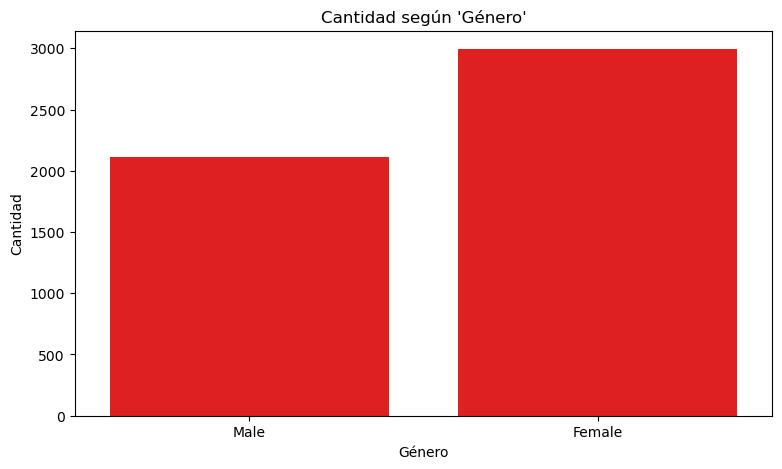

In [32]:
### Se crea la gráfica de género

plt.figure(figsize = (9,5))
sns.countplot(data = datosIctus, x="Genero", color ='red')
plt.title("Cantidad según 'Género'")
plt.xlabel("Género")
plt.ylabel("Cantidad")
plt.show()

#### Análisis de la gráfica de género

**Qué muestra.** La gráfica cuenta los registros `Male` y `Female` después de eliminar el único `Other`. La barra de `Female` es mayor: **2.994 personas (58,60 %)** frente a **2.115 (41,40 %)**. La diferencia es de **879 registros** y **17,20 puntos porcentuales**. La razón entre ambos tamaños es aproximadamente 1,42; por cada registro masculino hay 1,42 femeninos en la muestra analizada.

**Interpretación.** Existe mayor representación de la categoría femenina en este archivo. Esta composición puede influir en las estadísticas globales: una media general combina ambos grupos con pesos diferentes. Tampoco se ha demostrado que la muestra refleje la distribución de género de una población de referencia, pues no se conoce su selección. El color elegido para la barra no aporta información estadística ni modifica el resultado.

**Relación con derrame.** Esta gráfica no utiliza la etiqueta como agrupación. Por ello no permite concluir que un género tenga más propensión al derrame ni que una mayor cantidad de casos, si apareciera en otro gráfico, implique una mayor proporción. Para compararlos se necesita calcular `derrames del grupo / personas del grupo`, con denominadores 2.994 y 2.115, respectivamente. Los numeradores por género no se presentan aquí y no deben deducirse del tamaño de las barras.

**Cómo ampliar el análisis.** Elaborar una tabla de `Genero × Derrame`, informar el tamaño y los eventos de cada grupo y comparar edades y otras características entre ellos. Conviene revisar también el desempeño por género si se entrena un modelo: una buena métrica global puede esconder diferencias de sensibilidad entre grupos.

**Idea para el examen.** Un desequilibrio en un predictor y un desequilibrio en la variable objetivo son problemas distintos. Aquí se describe representación en `Genero`; el desbalance que determina la referencia de exactitud del clasificador se estudiará en `Derrame`.


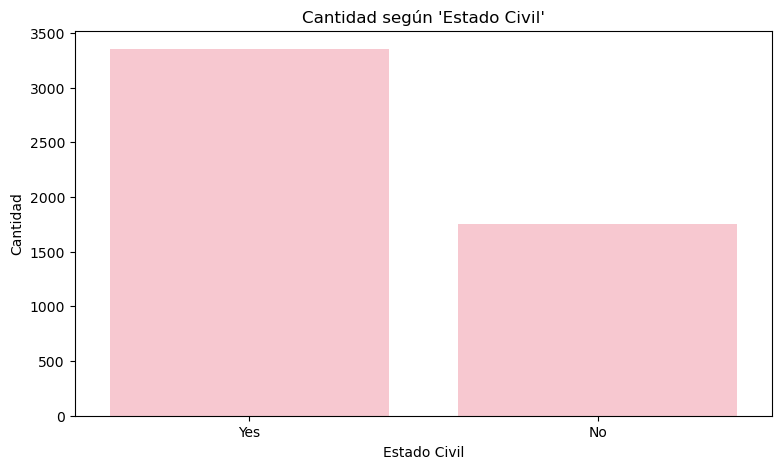

In [33]:
### Se crea la gráfica de género

plt.figure(figsize = (9,5))
sns.countplot(data = datosIctus, x='EdoCivil', color ='pink')
plt.title("Cantidad según 'Estado Civil'")
plt.xlabel("Estado Civil")
plt.ylabel("Cantidad")
plt.show()

#### Análisis de la gráfica de antecedente de matrimonio (`EdoCivil`)

**Qué muestra.** La categoría `Yes` tiene **3.353 registros (65,63 %)** y `No` tiene **1.756 (34,37 %)**. La diferencia de 1.597 equivale a **31,26 puntos porcentuales**; la razón de tamaños es aproximadamente 1,91. El archivo contiene casi dos personas con `Yes` por cada persona con `No`.

**Significado correcto.** Aunque el eje se titula «Estado Civil», la columna original es `ever_married`. Por tanto, `Yes` indica haber estado casado alguna vez y no necesariamente permanecer casado al momento del registro. Una persona divorciada o viuda podría cumplir esa definición. La variable no proporciona información suficiente para separar soltería, convivencia, matrimonio actual, divorcio y viudez.

**Interpretación y limitación.** La mayoría de la muestra tiene un antecedente de matrimonio según la codificación. Esto no demuestra un efecto del matrimonio sobre el derrame. Además, las oportunidades de haber estado casado pueden cambiar con la edad; si los grupos tienen estructuras de edad diferentes, una asociación sin ajuste podría reflejar esa composición. Este es un ejemplo de posible confusión que debe investigarse, no un efecto ya demostrado en los datos.

**Cómo ampliar el análisis.** Comparar la proporción de `Derrame = 1` dentro de `Yes` y `No`, describir sus edades y, después, evaluar si una diferencia persiste al controlar otras variables. Un gráfico de conteos apilados ayuda a ver tamaños absolutos; un gráfico normalizado al 100 % facilita comparar proporciones. Se deben identificar claramente sus denominadores.

**Idea para el examen.** Una traducción imprecisa del nombre de una variable puede llevar a una conclusión equivocada incluso si el código y los cálculos son correctos. La interpretación debe partir de la definición original.


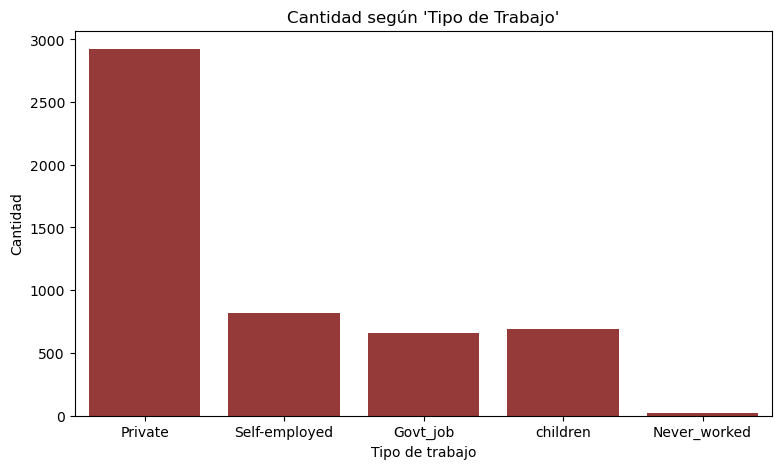

In [34]:
### Se crea la gráfica de tipo de trabajo

plt.figure(figsize = (9,5))
sns.countplot(data = datosIctus, x='TipoTrabajo', color ='brown')
plt.title("Cantidad según 'Tipo de Trabajo'")
plt.xlabel("Tipo de trabajo")
plt.ylabel("Cantidad")
plt.show()

#### Análisis de la gráfica de tipo de trabajo

**Qué muestra.** El mayor grupo es `Private`, con **2.924 registros (57,23 %)**. `Self-employed` reúne **819 (16,03 %)**; `children`, **687 (13,45 %)**; `Govt_job`, **657 (12,86 %)**; y `Never_worked`, **22 (0,43 %)**. La categoría privada supera a todas las demás combinadas: 2.924 frente a 2.185.

**Interpretación.** La muestra está dominada por personas clasificadas en trabajo privado. Sin embargo, la variable mezcla categorías de ocupación con condiciones de edad o trayectoria laboral: `children` identifica infancia y `Never_worked` una ausencia de experiencia laboral registrada. No es adecuado ordenar estas categorías como si fueran niveles de una escala única ni atribuirles directamente un nivel de exposición o de estrés.

**Relación con derrame.** Si el grupo privado tuviera más casos absolutos, parte de esa diferencia podría deberse simplemente a su tamaño. Para comparar se necesitan proporciones por categoría y revisar la composición etaria. En particular, comparar `children` con personas independientes sin considerar la edad combinaría dos dimensiones distintas. Las barras actuales no cuantifican exposición laboral, duración de empleo ni condiciones de trabajo.

**Categoría escasa.** `Never_worked` tiene solo 22 registros. Una sola observación con derrame cambiaría su proporción en `1/22 × 100 = 4,55` puntos porcentuales. Este cálculo ilustra su inestabilidad; no afirma que exista ese evento. El tamaño reducido requiere informar incertidumbre y evitar conclusiones generales a partir de porcentajes aparentemente grandes.

**Cómo ampliar el análisis.** Cruzar cada categoría con `Derrame`, presentar tamaños y eventos, comparar edades y estudiar si agrupar categorías tiene sentido conceptual. En modelado, una codificación numérica debe respetar que la variable es nominal; asignar números no crea un orden real.


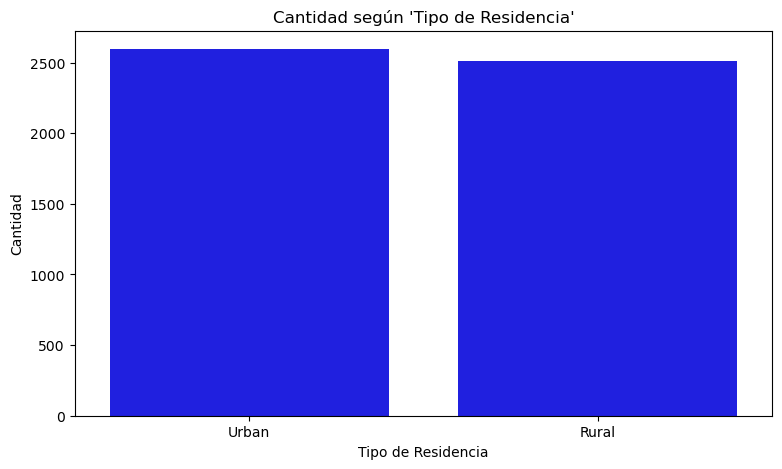

In [35]:
### Se crea la gráfica de tipo de residencia

plt.figure(figsize = (9,5))
sns.countplot(data = datosIctus, x='TipoResidencia', color ='blue')
plt.title("Cantidad según 'Tipo de Residencia'")
plt.xlabel("Tipo de Residencia")
plt.ylabel("Cantidad")
plt.show()

#### Análisis de la gráfica de tipo de residencia

**Qué muestra.** Hay **2.596 registros urbanos (50,81 %)** y **2.513 rurales (49,19 %)**. La diferencia es de 83 personas, equivalente a **1,62 puntos porcentuales**. La razón urbano/rural es aproximadamente 1,03, por lo que los grupos tienen tamaños muy similares.

**Interpretación.** El equilibrio evita que una categoría domine las estadísticas solo por ser mucho más numerosa. También proporciona una base conveniente para comparaciones posteriores. Aun así, se trata de equilibrio en una sola variable: no demuestra que ambas categorías estén equilibradas en edad, género, hipertensión, enfermedad cardiaca o proporción de derrame.

**Qué no se puede concluir.** Las barras no indican que el lugar de residencia sea irrelevante ni que ambos grupos tengan la misma proporción de eventos. Tampoco prueban igualdad de acceso a atención, recursos o estilos de vida, porque esas variables no se han medido aquí. Conocer el tamaño de los grupos y conocer su relación con la etiqueta son preguntas diferentes.

**Cómo ampliar el análisis.** Obtener los eventos y no eventos de cada residencia, calcular porcentajes dentro de cada grupo y comparar las características de sus integrantes. Si las tasas fueran parecidas, habría que considerar su incertidumbre antes de afirmar equivalencia: «no observar una diferencia clara» no es lo mismo que demostrar igualdad. Si fueran diferentes, seguiría siendo necesario revisar posibles factores de confusión.

**Idea para el examen.** Un predictor puede estar perfectamente equilibrado y la etiqueta seguir muy desbalanceada. En este taller la residencia está casi al 50/50, mientras que los derrames representan solo el 4,87 % del total. El equilibrio de `TipoResidencia` no elimina el problema de evaluación de la clase positiva.


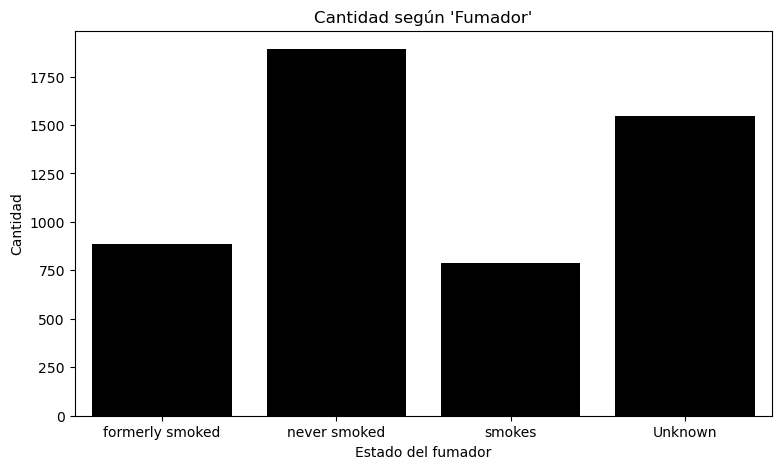

In [36]:
### Se crea la gráfica de fumador

plt.figure(figsize = (9,5))
sns.countplot(data = datosIctus, x='Fumador', color ='black')
plt.title("Cantidad según 'Fumador'")
plt.xlabel("Estado del fumador")
plt.ylabel("Cantidad")
plt.show()

#### Análisis de la gráfica de historial de tabaquismo

**Qué muestra.** `never smoked` reúne **1.892 registros (37,03 %)**; `Unknown`, **1.544 (30,22 %)**; `formerly smoked`, **884 (17,30 %)**; y `smokes`, **789 (15,44 %)**. La categoría individual más frecuente es nunca haber fumado, pero no representa más de la mitad de la muestra. Exfumadores y fumadores actuales suman 1.673 personas, **32,75 % del total**.

**Interpretación de los denominadores.** El 15,44 % corresponde a fumadores actuales entre los 5.109 registros. Si se consideran únicamente los 3.565 con historial conocido, la proporción de fumadores actuales es `789/3565 × 100 = 22,13 %`. Ambos cálculos son correctos, pero responden preguntas diferentes. Presentar el segundo como si representara a toda la muestra ignoraría a casi un tercio de las personas.

**Información desconocida.** `Unknown` no significa «nunca fumó» ni «no fuma actualmente». Eliminar esa categoría retiraría el 30,22 % de los registros y podría cambiar sustancialmente la composición. Mantenerla permite reconocer el desconocimiento; no resuelve por sí mismo el posible sesgo. Conviene investigar su relación con la edad y con otros datos disponibles, sin asumir de antemano por qué no se registró la información.

**Relación con derrame.** Las barras describen historia de consumo, no eventos. No permiten ordenar el riesgo de las categorías. Una comparación posterior también debería considerar edad y otras características, y recordar que no se dispone de cantidad consumida, duración, fecha de abandono ni secuencia temporal respecto del derrame.

**Cómo ampliar el análisis.** Cruzar las cuatro categorías con `Derrame`, informar los eventos y denominadores y repetir la comparación en el subconjunto de historial conocido como análisis de sensibilidad. Una diferencia entre ambos análisis indicaría dependencia respecto del tratamiento de la información faltante; no justificaría elegir solo el resultado más llamativo.


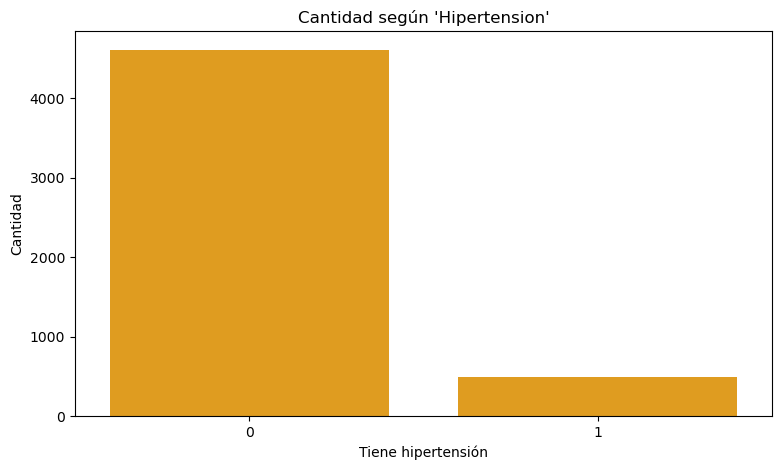

In [37]:
### Se crea la gráfica de hipertensión

plt.figure(figsize = (9,5))
sns.countplot(data = datosIctus, x='Hipertension', color ='orange')
plt.title("Cantidad según 'Hipertension'")
plt.xlabel("Tiene hipertensión")
plt.ylabel("Cantidad")
plt.show()

#### Análisis de la gráfica de hipertensión

**Qué muestra.** La variable está codificada como 0/1. La media completa guardada, multiplicada por 5.109, permite recuperar **498 registros con 1 (9,75 %)** y **4.611 con 0 (90,25 %)**. Hay aproximadamente 9,26 registros con 0 por cada registro con 1. El código numérico representa una categoría; la distancia 0–1 no es una diferencia de presión arterial medida.

**Interpretación.** La mayor parte de la muestra no tiene hipertensión registrada bajo esa codificación. Esta proporción describe el archivo y no puede trasladarse automáticamente a la población general. Tampoco significa que el 90,25 % restante carezca de cualquier otra condición, pues el indicador solo se refiere a una variable y su calidad depende de cómo se registró.

**Relación con derrame.** Para analizar una asociación se deben comparar `derrames entre los 498 con hipertensión / 498` y `derrames entre los 4611 sin hipertensión / 4611`. Las cantidades de eventos de esos grupos no están en esta gráfica. Un conteo absoluto mayor en el grupo sin hipertensión podría coexistir con una proporción mayor en el grupo con hipertensión, porque sus denominadores difieren mucho.

**Límites e implicaciones.** La barra pequeña no implica que el predictor sea poco útil. Su capacidad de discriminar depende de cómo cambie la etiqueta al condicionar por él y por otras variables. Asimismo, una asociación descriptiva no demuestra que el indicador sea la causa del evento ni permite reconstruir su secuencia temporal.

**Cómo ampliar el análisis.** Construir una tabla 2 × 2 con hipertensión y derrame, informar proporciones dentro de cada categoría, revisar edades y calcular intervalos de confianza. Si se aplica una prueba de asociación, hay que revisar los conteos esperados y reportar tamaño del efecto, no solo un valor p.


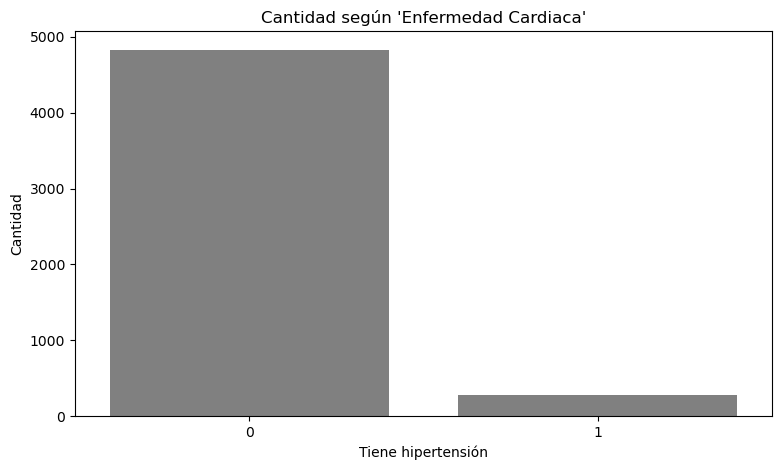

In [38]:
### Se crea la gráfica de enfermedad cardiaca

plt.figure(figsize = (9,5))
sns.countplot(data = datosIctus, x='EnfCardiaca', color ='gray')
plt.title("Cantidad según 'Enfermedad Cardiaca'")
plt.xlabel("Tiene hipertensión")
plt.ylabel("Cantidad")
plt.show()

#### Análisis de la gráfica de enfermedad cardiaca

**Qué muestra.** A partir de la media completa de `EnfCardiaca` y el tamaño muestral se obtienen **276 registros con 1 (5,40 %)** y **4.833 con 0 (94,60 %)**. La razón de tamaños es aproximadamente 17,51 registros con 0 por cada registro con 1. Esta es una característica poco frecuente dentro de la muestra, aunque su frecuencia no determina por sí sola su asociación con la respuesta.

**Corrección de lectura.** El título y la columna graficada corresponden a enfermedad cardiaca, pero el eje X guardado dice «Tiene hipertensión». Es una etiqueta copiada de la gráfica anterior. Debe leerse como **«Enfermedad cardiaca registrada: 0 = no, 1 = sí»**. En la próxima ejecución se recomienda corregir `plt.xlabel(...)`; el análisis se realiza sobre `EnfCardiaca`, tal como indica el código.

**Interpretación.** Predomina el valor 0. El indicador no informa qué enfermedad se registró, su intensidad, tratamiento ni duración, por lo que no permite describir perfiles cardiológicos específicos. También debe evitarse interpretar 0 como ausencia comprobada de toda patología si no se conoce el protocolo de registro.

**Relación con derrame.** La pregunta relevante es si la proporción de derrames entre las 276 personas con valor 1 difiere de la de las 4.833 con valor 0. La gráfica no ofrece esos numeradores. El grupo pequeño puede producir estimaciones más variables y requiere revisar cuántos eventos contiene antes de extraer conclusiones.

**Cómo ampliar el análisis.** Elaborar el cruce con `Derrame`, informar tamaños y proporciones, examinar edades y el cruce con hipertensión. Los indicadores de hipertensión y enfermedad cardiaca pueden coincidir en una misma persona; sus conteos no deben sumarse para calcular personas con «alguna condición» sin descontar la intersección.


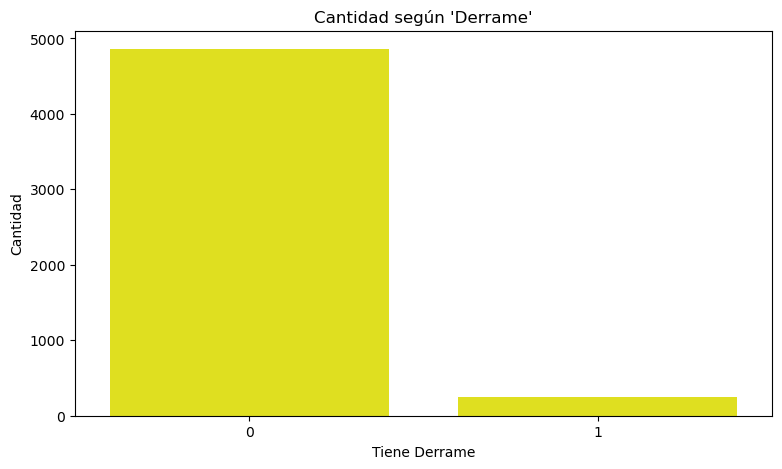

In [39]:
### Se crea la gráfica de derrame

plt.figure(figsize = (9,5))
sns.countplot(data = datosIctus, x='Derrame', color ='yellow')
plt.title("Cantidad según 'Derrame'")
plt.xlabel("Tiene Derrame")
plt.ylabel("Cantidad")
plt.show()

#### Análisis de la gráfica de derrame: desbalance de la etiqueta

**Qué muestra.** Hay **249 registros con `Derrame = 1` (4,87 %)** y **4.860 con `Derrame = 0` (95,13 %)**. Por cada caso positivo aparecen aproximadamente **19,52 negativos**. El total coincide con 5.109. El desbalance es una propiedad central de la respuesta, no un detalle estético de la gráfica.

**Interpretación.** El evento etiquetado es poco frecuente en este archivo. El 4,87 % es una proporción muestral de registros positivos; no es una incidencia anual ni una probabilidad individual futura, porque faltan periodo de seguimiento y diseño de muestreo. La gráfica tampoco describe la gravedad o el momento de los eventos.

**Consecuencia para la evaluación.** Una regla que predijera siempre 0 acertaría `4860/5109 = 95,13 %`, aun cuando no identificara ninguno de los 249 positivos. En toda esta muestra tendría **TN = 4.860, FP = 0, FN = 249 y TP = 0**. Su sensibilidad para la clase 1 sería 0 %. Su precisión positiva no estaría definida porque no emitiría predicciones positivas; algunos programas la reportan como 0 por convención. Esta regla es una referencia calculable, no un modelo entrenado.

**Qué se debe evaluar.** Además de exactitud, se necesitan matriz de confusión, sensibilidad de la clase positiva, precisión positiva, F1 positivo y métricas sobre puntuaciones como PR-AUC. Un promedio ponderado entre clases puede verse alto por el predominio de la clase 0; por ello hay que identificar qué clase y qué promedio resume cada métrica.

**Preparación de un modelo.** Separar entrenamiento, validación y prueba, comprobar la representación de los positivos y aplicar cualquier remuestreo solo en entrenamiento. La validación debe incluir el ajuste del umbral y la comparación de estrategias; el conjunto de prueba se reserva para una evaluación final. Reequilibrar el archivo completo antes de dividir puede contaminar la evaluación o alterar la distribución que se intenta medir.


### **Variables cuantitativas**

### Cómo leer histogramas, densidades y valores extremos

Un histograma divide el eje numérico en intervalos y cuenta cuántos registros caen en cada uno. En las tres gráficas individuales se solicitan **40 intervalos**; cambiar su anchura puede alterar la apariencia de picos y huecos. La línea KDE es un suavizado: ayuda a observar la forma general, pero no es una curva ajustada de normalidad ni una prueba estadística. Véanse las explicaciones de [histogramas en Seaborn](https://seaborn.pydata.org/generated/seaborn.histplot.html) y de [estimación KDE](https://seaborn.pydata.org/generated/seaborn.kdeplot.html).

En una distribución asimétrica conviene describir centro, dispersión y colas. La media utiliza todos los valores y puede desplazarse con los extremos; la mediana divide los datos ordenados en dos mitades. Los cuartiles permiten calcular `IQR = Q3 − Q1`; las cercas `Q1 − 1,5 × IQR` y `Q3 + 1,5 × IQR` sirven para **señalar observaciones que revisar**, no para demostrar que son errores. El taller no ha calculado esos cuartiles, por lo que no se inventan umbrales ni cantidades de atípicos.

La apariencia de una distribución tampoco determina por sí sola qué transformación usar. Antes de eliminar extremos o aplicar logaritmos se debe revisar la fuente, el objetivo y el efecto sobre la información, dejando documentada la decisión.


In [40]:
df03.printSchema()

root
 |-- id: integer (nullable = true)
 |-- Genero: string (nullable = true)
 |-- Edad: integer (nullable = true)
 |-- Hipertension: integer (nullable = true)
 |-- EnfCardiaca: integer (nullable = true)
 |-- EdoCivil: string (nullable = true)
 |-- TipoTrabajo: string (nullable = true)
 |-- TipoResidencia: string (nullable = true)
 |-- NivelGlucosa: double (nullable = true)
 |-- IMC: double (nullable = true)
 |-- Fumador: string (nullable = true)
 |-- Derrame: integer (nullable = true)



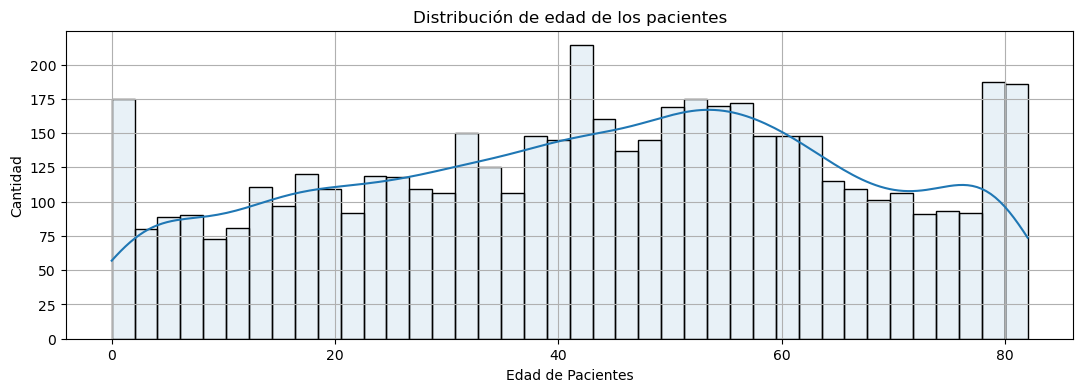

In [41]:
### Se crea la gráfica de edad

plt.figure(figsize=(13,4))
sns.histplot(data = datosIctus, x='Edad', bins =40, kde = True, alpha = 0.1)
plt.title("Distribución de edad de los pacientes")
plt.xlabel("Edad de Pacientes")
plt.ylabel("Cantidad")
plt.grid()
plt.show()

#### Análisis del histograma de edad

**Qué muestra.** La edad transformada abarca **0 a 82 años**, con media **43,22** y desviación estándar muestral **22,63**. El histograma incluye población infantil, adulta y de edades avanzadas. La mayor concentración visual se encuentra en amplios sectores de la adultez media, con un máximo del suavizado aproximadamente en torno a los 50–55 años. También se observan barras elevadas cerca de los extremos de edad y fluctuaciones entre intervalos.

**Forma y dispersión.** La distribución es amplia y no presenta una campana simétrica clara. La media resume el centro aritmético, pero no implica que la mayoría tenga exactamente 43 años. La desviación indica heterogeneidad; no puede utilizarse para aplicar automáticamente la regla del 68–95–99,7 %, que presupone una distribución aproximadamente normal. La gráfica no constituye una prueba formal de normalidad.

**Efecto de la preparación.** El mínimo 0 se interpreta teniendo en cuenta que el código truncó edades decimales: algunos valores originalmente menores de un año pueden representarse como cero. No se debe declarar que esos registros son errores sin inspeccionarlos. La conversión a entero y los límites de los intervalos también pueden contribuir a la forma de las barras. El KDE puede suavizar una variable ahora discreta y sugerir valores intermedios que no son edades enteras observadas.

**Relación con derrame.** Esta gráfica contiene ambas clases mezcladas. Por tanto, describe la edad de toda la muestra y no identifica todavía la edad típica de los 249 eventos. Un grupo etario numeroso puede aportar muchos casos por su tamaño; comparar proporciones de derrame requiere denominadores dentro de cada tramo.

**Cómo ampliar el análisis.** Calcular mediana, cuartiles y conteos por intervalos de edad con límites explícitos. Después, comparar edades entre `Derrame = 0` y `1` y obtener proporciones por tramo. Es necesario diferenciar un patrón observado entre personas de edades distintas de un cambio longitudinal en una misma persona.


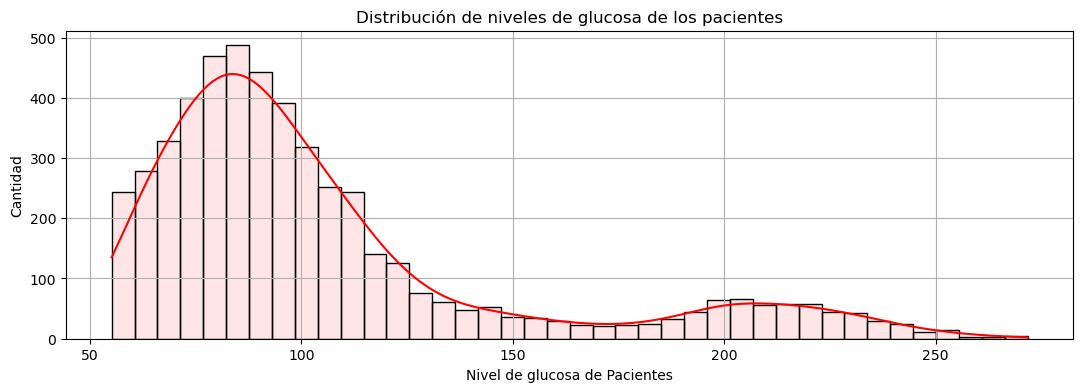

In [42]:
### Se crea la gráfica de nivel de glucosa

plt.figure(figsize=(13,4))
sns.histplot(data = datosIctus, x='NivelGlucosa', bins =40, kde = True, alpha = 0.1, color = 'red')
plt.title("Distribución de niveles de glucosa de los pacientes")
plt.xlabel("Nivel de glucosa de Pacientes")
plt.ylabel("Cantidad")
plt.grid()
plt.show()

#### Análisis del histograma de nivel de glucosa

**Qué muestra.** Los valores van de **55,12 a 271,74**, con media **106,14** y desviación estándar **45,29**. Visualmente, la mayor concentración se encuentra aproximadamente entre 70 y 110, con el pico principal cerca de 85–95. A partir de esa zona la frecuencia disminuye y aparece una cola prolongada hacia valores mayores. También se distingue una concentración secundaria más pequeña alrededor de 190–220.

**Forma de la distribución.** Se observa asimetría positiva. La cola derecha puede elevar la media respecto de la zona donde se agrupan más registros; para cuantificar esa diferencia haría falta calcular la mediana. La concentración secundaria sugiere heterogeneidad y merece exploración, pero no demuestra por sí sola dos grupos clínicos ni dos distribuciones normales. La elección de intervalos y el suavizado influyen en cómo se percibe.

**Valores altos.** Los registros de la cola no se deben eliminar automáticamente. Primero hay que verificar unidades, formato y protocolo de medición, y determinar si son valores plausibles o errores de captura. El archivo no documenta aquí condiciones de toma de muestra ni criterios diagnósticos; por eso no se clasifica a las personas a partir de umbrales clínicos ni se identifica una enfermedad a partir de esta gráfica.

**Relación con derrame.** El histograma mezcla los 4.860 negativos y 249 positivos. Debido al fuerte predominio de la clase 0, la forma global refleja principalmente ese grupo. La presencia de valores altos en toda la muestra no dice qué proporción corresponde a derrames. Esa comparación requiere separar las distribuciones o calcular tasas por intervalos, conservando denominadores.

**Cómo ampliar el análisis.** Obtener mediana, IQR, percentiles y estadísticas separadas por etiqueta; después revisar el papel de la edad y otros indicadores. Una posible transformación logarítmica debe decidirse según el modelo y validarse; una distribución asimétrica no obliga a transformar para cualquier método.


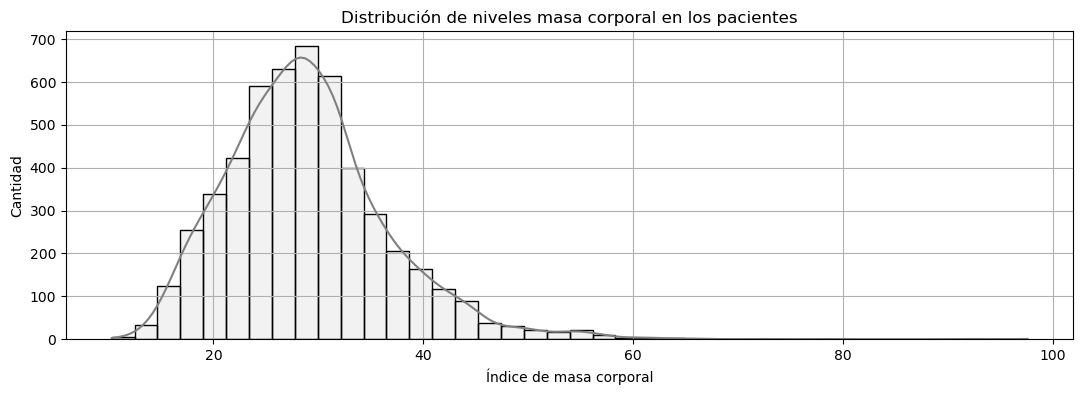

In [43]:
### Se crea la gráfica de IMC

plt.figure(figsize=(13,4))
sns.histplot(data = datosIctus, x='IMC', bins =40, kde = True, alpha = 0.1, color = 'gray')
plt.title("Distribución de niveles masa corporal en los pacientes")
plt.xlabel("Índice de masa corporal")
plt.ylabel("Cantidad")
plt.grid()
plt.show()

#### Análisis del histograma de IMC

**Qué muestra.** Después de la imputación, el IMC tiene media **28,92**, desviación estándar **7,73** y rango de **10,3 a 97,6**. La mayor concentración visual se sitúa aproximadamente entre 20 y 35, con un pico cerca de 28–32. La distribución presenta una cola derecha y pocos registros visualmente alejados de la zona central. La escala extendida hasta valores cercanos a 100 hace que los extremos de muy baja frecuencia apenas se distingan.

**Interpretación estadística.** El promedio global no describe a todas las personas y no debe convertirse en una clasificación individual. La muestra incluye edades muy distintas; mezclar población infantil y adulta limita cualquier interpretación clínica conjunta. La asimetría y los extremos justifican complementar la media con mediana e IQR, que todavía no se muestran calculados.

**Efecto de la imputación.** Los 201 faltantes se sustituyeron por promedios de grupos, muchos próximos a la zona central. Esto puede aumentar la concentración alrededor de esos valores y reducir la variabilidad respecto de una situación en la que se conocieran los valores reales. No se debe atribuir toda la forma del histograma a diferencias originales entre pacientes. Además, las salidas conservan el posible error de referencia del promedio masculino de 80–89 años explicado antes.

**Revisión de extremos.** El máximo 97,6 merece comprobación de la fuente, unidades y plausibilidad, pero el máximo por sí solo no prueba un error. Un diagrama de caja y cercas de IQR ayudarían a seleccionar observaciones para revisar. Eliminar automáticamente los valores más altos podría quitar información relevante y cambiar la comparación entre etiquetas.

**Cómo ampliar el análisis.** Comparar el histograma de IMC observado con el de IMC imputado, informar qué porcentaje fue rellenado en cada clase y revisar la distribución por edad. Finalmente, contrastar los grupos con y sin derrame sin asumir que la forma global implica poder predictivo.


### Combinación de variables cuantitativas con la etiqueta de derrame

Las tres gráficas siguientes separan `Derrame = 0` y `Derrame = 1` con `hue` y `col`. Usan `stat='density'` y `common_norm=False`, por lo que cada grupo se normaliza de manera independiente. Así se comparan formas de distribución aunque los tamaños sean 4.860 y 249.

Para un intervalo de anchura $h$, la altura aproximada del histograma de una clase es $n_{intervalo}/(n_{clase}h)$. **El área**, no la suma de alturas ni la altura de una barra aislada, representa una proporción. Con esta normalización el área total de cada grupo es aproximadamente 1. No hay tantos positivos como negativos aunque sus barras puedan tener alturas semejantes. Este uso se explica en la [guía de distribuciones de Seaborn](https://seaborn.pydata.org/tutorial/distributions.html).

Estas gráficas muestran cómo se distribuye una variable **dada la etiqueta**, es decir, $P(X\mid D)$ en términos de intervalos. No muestran directamente $P(D=1\mid X)$, que responde a otra pregunta. Una densidad alta de glucosa entre los casos no es una probabilidad de derrame para una persona con esa glucosa; también importan la frecuencia base y la distribución de los no casos.


<Figure size 1300x400 with 0 Axes>

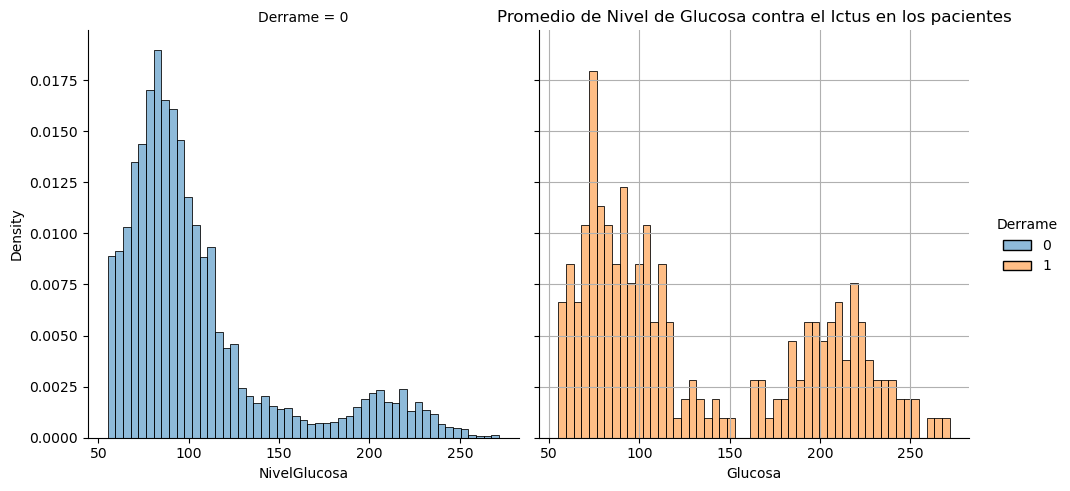

In [44]:
### Se requiere observar el Promedio de Nivel de Glucosa contra el Ictus en los pacientes

plt.figure(figsize=(13,4))
sns.displot(data = datosIctus, x = 'NivelGlucosa', hue = 'Derrame', col = 'Derrame', stat = 'density', common_norm = False)
plt.title("Promedio de Nivel de Glucosa contra el Ictus en los pacientes")
plt.xlabel("Glucosa")
plt.ylabel("Densidad")
plt.grid()
plt.show()

**Nota sobre títulos y construcción de los paneles.** La gráfica anterior no calcula un promedio entre clases: distribuye el predictor `NivelGlucosa`, cuyo nombre original ya contiene la palabra `avg`. Para evitar confundir ambas operaciones, se recomienda el título «Distribución del nivel promedio de glucosa según derrame».

`sns.displot` administra su propia figura y devuelve un `FacetGrid`. El `plt.figure(...)` previo crea una figura vacía, como indica la salida «0 Axes»; los cambios posteriores con `plt.title` y `plt.xlabel` pueden aplicarse solo al eje activo. Para una próxima ejecución es más claro usar `g = sns.displot(...)`, luego `g.set_axis_labels(...)`, `g.set_titles(...)` y `g.figure.suptitle(...)`. La [documentación de `displot`](https://seaborn.pydata.org/generated/seaborn.displot.html) describe esta interfaz. Las figuras guardadas se conservan para sostener las comparaciones analizadas.


#### Análisis de la distribución de glucosa según derrame

**Qué se compara.** El panel de `Derrame = 0` reúne 4.860 registros y el de `Derrame = 1`, 249. Cada distribución se normaliza por separado. Por ello se comparan la concentración y la forma de glucosa dentro de cada clase, no los números absolutos de pacientes ni los promedios de cada grupo.

**Patrón observado.** En el grupo sin derrame predomina una concentración en valores aproximadamente entre 70 y 110, con una cola derecha y una concentración secundaria menor cerca de 200. Entre los casos con derrame se observa una distribución más irregular, con una zona de concentración en valores inferiores y una presencia relativa visualmente mayor alrededor de 180–230. Los paneles sugieren una asociación entre la distribución de glucosa y la etiqueta, especialmente en la zona alta.

**Solapamiento.** Ambos grupos contienen valores bajos, intermedios y altos. No hay un punto de corte evidente que separe todas las observaciones. Algunas personas con glucosa alta están en la clase 0 y algunas con valores de la zona principal están en la clase 1. Por tanto, esta variable por sí sola no clasifica sin errores ni permite atribuir un diagnóstico individual.

**Qué no se ha cuantificado.** La gráfica no muestra medias, medianas, tamaños del efecto ni significación estadística por clase. No sería correcto inventar una diferencia media exacta o afirmar que una asociación permanece después de ajustar por edad. El panel positivo tiene muchas menos observaciones y su histograma puede ser más irregular por ese tamaño; la altura puntual de un pico no debe sobreinterpretarse.

**Cómo ampliar el análisis.** Calcular media, mediana, cuartiles y número de registros por clase, informar diferencias con incertidumbre y comparar proporciones de eventos por intervalos de glucosa. Después, examinar si el patrón persiste al incorporar edad, hipertensión y otras variables. La gráfica describe una asociación muestral; no establece que una variación de glucosa cause el evento ni que preceda temporalmente al registro de derrame.


<Figure size 1300x400 with 0 Axes>

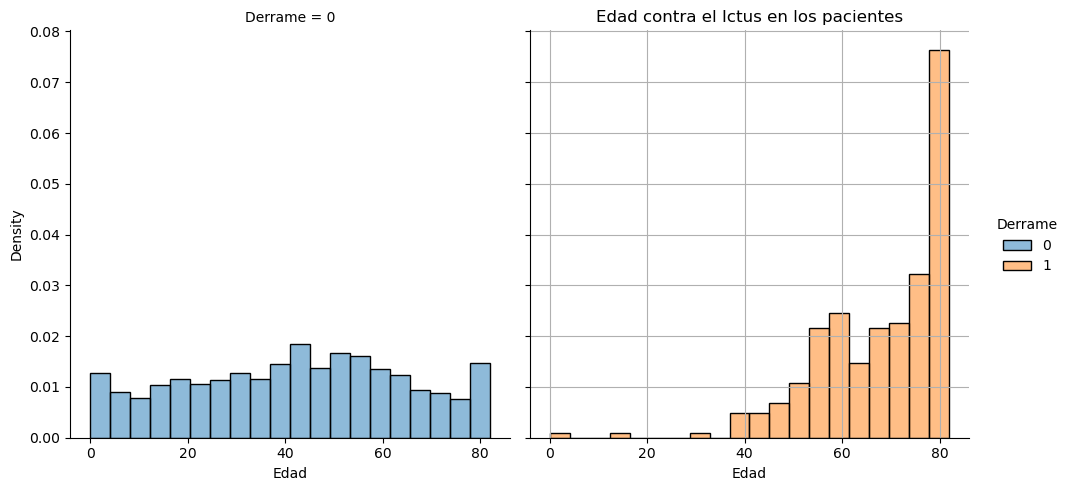

In [45]:
### Se requiere observar Edad contra pacientes con Ictus

plt.figure(figsize=(13,4))
sns.displot(data = datosIctus, x = 'Edad', hue = 'Derrame', col = 'Derrame', stat = 'density', common_norm = False)
plt.title("Edad contra el Ictus en los pacientes")
plt.xlabel("Edad")
plt.ylabel("Densidad")
plt.grid()
plt.show()

#### Análisis de la distribución de edad según derrame

**Patrón observado.** En `Derrame = 0` aparecen observaciones a lo largo de casi todo el rango de edad. En `Derrame = 1` la distribución está mucho más concentrada en edades avanzadas: visualmente predominan registros desde alrededor de 50 años y la densidad aumenta hacia el extremo de 75–82. También hay algunos casos en edades menores, por lo que no se puede afirmar que el evento solo aparezca en personas mayores.

**Interpretación.** Dentro de las comparaciones mostradas, la edad ofrece un contraste visual especialmente claro entre clases. Esto justifica estudiarla como posible predictor y como variable de ajuste. No permite asegurar que sea «la más importante» en un modelo: esa afirmación requiere entrenar y evaluar un modelo definido, y la importancia puede cambiar con la presencia de otras variables y sus asociaciones.

**Denominador correcto.** El panel muestra la distribución de edades **entre quienes tienen la etiqueta de derrame** y la distribución entre quienes no la tienen. No equivale a la proporción de personas con derrame dentro de cada edad. Para esa segunda pregunta se necesita dividir los eventos de un tramo entre todas las personas del mismo tramo. Tampoco puede leerse una altura de densidad de 0,08 como «8 % de riesgo de derrame».

**Solapamiento y límites.** Hay personas de edades avanzadas en ambos paneles. La edad no determina por sí sola la etiqueta y no ofrece una regla perfecta. Las barras cerca del máximo pueden estar influidas por el agrupamiento de los intervalos y por el límite superior de 82 años. El archivo no demuestra cómo se comportaría el patrón por encima de esa edad.

**Cómo ampliar el análisis.** Definir tramos con suficiente número de observaciones, calcular eventos, totales e intervalos de confianza por tramo y comparar medianas por clase. Luego revisar si asociaciones de matrimonio, trabajo o comorbilidades cambian al considerar la edad. Esto permite investigar confusión y distinguir una asociación directa de una que refleje la composición etaria.


<Figure size 1300x400 with 0 Axes>

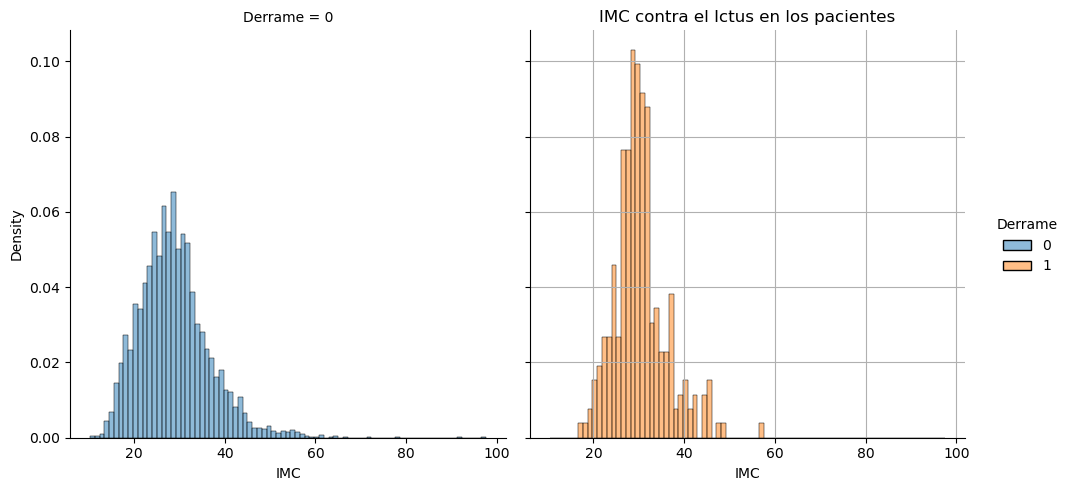

In [46]:
### Se requiere observar el IMC contra pacientes con Ictus

plt.figure(figsize=(13,4))
sns.displot(data = datosIctus, x = 'IMC', hue = 'Derrame', col = 'Derrame', stat = 'density', common_norm = False)
plt.title("IMC contra el Ictus en los pacientes")
plt.xlabel("IMC")
plt.ylabel("Densidad")
plt.grid()
plt.show()

#### Análisis de la distribución de IMC según derrame

**Patrón observado.** Los dos paneles concentran buena parte de su masa aproximadamente entre 20 y 40. En la clase 0 se aprecia una distribución más amplia, con cola derecha y valores extremos que se extienden mucho más allá de la zona principal. En la clase 1 hay una concentración visual marcada alrededor de 28–35 y un histograma más irregular. Existe **un solapamiento considerable** entre los grupos.

**Interpretación.** La separación visual del IMC es menos clara que la observada para la edad. Esto sugiere que un único umbral de IMC tendría dificultades para distinguir ambas clases en esta muestra. Sin embargo, el solapamiento no demuestra ausencia de asociación ni inutilidad dentro de un modelo: puede haber relaciones no lineales o combinaciones con edad y otros predictores que estas distribuciones individuales no revelan.

**Efecto del tamaño y de la imputación.** El grupo positivo tiene solo 249 registros; es esperable mayor irregularidad al dividirlo en muchos intervalos. A ello se suma que algunos IMC fueron imputados con medias de género y edad, próximas a la zona del pico. No es posible atribuir el pico exclusivamente a valores medidos. Para valorarlo hay que conocer cuántos IMC faltaban en cada clase y comparar el subconjunto observado con el imputado.

**Qué no se puede concluir.** La presencia de extremos más altos en la clase 0 no demuestra que un IMC elevado proteja frente al derrame. El grupo negativo es 19,52 veces mayor y tiene más oportunidades de contener valores extremos, incluso al comparar gráficas normalizadas. Tampoco se puede afirmar una igualdad de medias ni una diferencia estadísticamente significativa sin cálculos adicionales.

**Cómo ampliar el análisis.** Calcular mediana e IQR por clase, revisar extremos sin eliminarlos automáticamente y repetir la comparación con IMC observado. Posteriormente, evaluar el IMC junto con edad y las demás variables y comprobar el rendimiento en datos reservados. El análisis debe repetirse después de corregir la referencia masculina de imputación si existen filas afectadas.


## Síntesis del análisis exploratorio

La exploración utilizó **5.109 registros**, después de excluir un registro de la categoría `Other`. Dentro de esta muestra se identificaron **249 positivos y 4.860 negativos**, lo que evidencia un fuerte desbalance de la etiqueta.

Se encontraron **201 valores faltantes de IMC**, completados para la exploración mediante promedios por género y tramo de edad. También se conservaron **1.544 registros con tabaquismo `Unknown`**, interpretados como información desconocida.

Las distribuciones muestran diferencias visuales entre las clases, especialmente en edad. Estas observaciones permiten formular hipótesis y orientar la preparación, pero no demuestran causalidad ni importancia predictiva por sí solas.

Para la comparación final de modelos se retoma `df01`, anterior al filtro de género y a la imputación exploratoria. Por ello, el modelado conserva **5.110 registros**, incluida la categoría `Other`, y mantiene los decimales de edad.

La diferencia entre los tamaños de exploración y modelado corresponde a decisiones explícitas de preparación. Las métricas finales pertenecen exclusivamente al bloque de cinco modelos que comienza en **“Preparación y diseño de la comparación”**.

## Se requiere generar una nueva columna que sea 'AltoRiesgo'.
- Nivel de Glucosa < 126 y Edad > 41, = 1 (Alto riesgo)
- Caso contrario, = 0 (Bajo riesgo)

In [47]:
df03.printSchema()

root
 |-- id: integer (nullable = true)
 |-- Genero: string (nullable = true)
 |-- Edad: integer (nullable = true)
 |-- Hipertension: integer (nullable = true)
 |-- EnfCardiaca: integer (nullable = true)
 |-- EdoCivil: string (nullable = true)
 |-- TipoTrabajo: string (nullable = true)
 |-- TipoResidencia: string (nullable = true)
 |-- NivelGlucosa: double (nullable = true)
 |-- IMC: double (nullable = true)
 |-- Fumador: string (nullable = true)
 |-- Derrame: integer (nullable = true)



In [48]:
df03.show(5)

+-----+------+----+------------+-----------+--------+-------------+--------------+------------+-----+---------------+-------+
|   id|Genero|Edad|Hipertension|EnfCardiaca|EdoCivil|  TipoTrabajo|TipoResidencia|NivelGlucosa|  IMC|        Fumador|Derrame|
+-----+------+----+------------+-----------+--------+-------------+--------------+------------+-----+---------------+-------+
| 9046|  Male|  67|           0|          1|     Yes|      Private|         Urban|      228.69| 36.6|formerly smoked|      1|
|51676|Female|  61|           0|          0|     Yes|Self-employed|         Rural|      202.21|30.78|   never smoked|      1|
|31112|  Male|  80|           0|          1|     Yes|      Private|         Rural|      105.92| 32.5|   never smoked|      1|
|60182|Female|  49|           0|          0|     Yes|      Private|         Urban|      171.23| 34.4|         smokes|      1|
| 1665|Female|  79|           1|          0|     Yes|Self-employed|         Rural|      174.12| 24.0|   never smoked| 

In [49]:
df04 = df03.withColumn('AltoRiesgo', F.when(((F.col('Edad') > 41) & (F.col('NivelGlucosa') < 126)), 1).otherwise(0))
df04.show(5)

+-----+------+----+------------+-----------+--------+-------------+--------------+------------+-----+---------------+-------+----------+
|   id|Genero|Edad|Hipertension|EnfCardiaca|EdoCivil|  TipoTrabajo|TipoResidencia|NivelGlucosa|  IMC|        Fumador|Derrame|AltoRiesgo|
+-----+------+----+------------+-----------+--------+-------------+--------------+------------+-----+---------------+-------+----------+
| 9046|  Male|  67|           0|          1|     Yes|      Private|         Urban|      228.69| 36.6|formerly smoked|      1|         0|
|51676|Female|  61|           0|          0|     Yes|Self-employed|         Rural|      202.21|30.78|   never smoked|      1|         0|
|31112|  Male|  80|           0|          1|     Yes|      Private|         Rural|      105.92| 32.5|   never smoked|      1|         1|
|60182|Female|  49|           0|          0|     Yes|      Private|         Urban|      171.23| 34.4|         smokes|      1|         0|
| 1665|Female|  79|           1|         

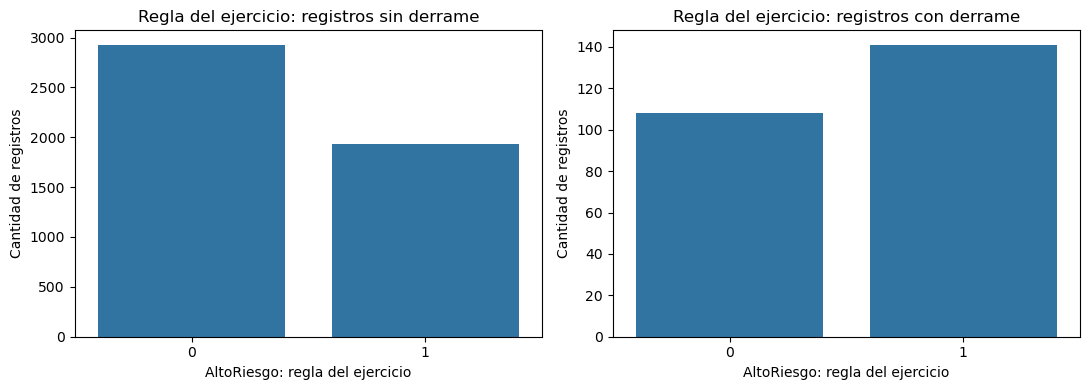

In [50]:
# Comparar la regla del ejercicio dentro de cada clase de Derrame.
datos2 = df04.toPandas()

# loc utiliza corchetes para seleccionar filas.
ictusA = datos2.loc[datos2["Derrame"] == 1]
ictusB = datos2.loc[datos2["Derrame"] == 0]

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

sns.countplot(
    data=ictusB,
    x="AltoRiesgo",
    ax=axes[0]
)

sns.countplot(
    data=ictusA,
    x="AltoRiesgo",
    ax=axes[1]
)

axes[0].set_title("Regla del ejercicio: registros sin derrame")
axes[1].set_title("Regla del ejercicio: registros con derrame")

for ax in axes:
    ax.set_xlabel("AltoRiesgo: regla del ejercicio")
    ax.set_ylabel("Cantidad de registros")

plt.tight_layout()
plt.show()

La columna AltoRiesgo reproduce la regla propuesta en el ejercicio: edad mayor de 41 años y glucosa menor de 126. Se conserva como una transformación académica y no se interpreta como una clasificación clínica validada. El modelado posterior utiliza las variables originales y excluye esta regla derivada.

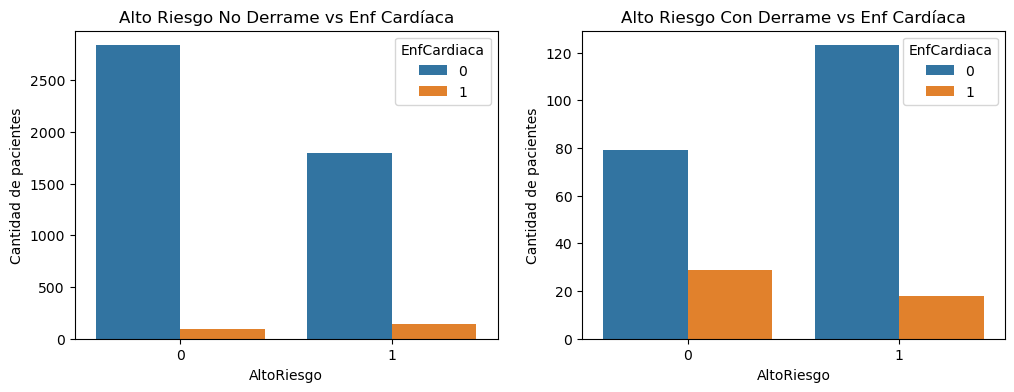

In [51]:
# Graficas de alto riesgo sin derrame vs enfermedad cardiaca

pandasDatos = df04.toPandas()

fig, matrix = plt.subplots(1,2, figsize=(12,4))

matrix[0].set_title("Alto Riesgo No Derrame vs Enf Cardíaca")
matrix[0].set_ylabel("Cantidad de pacientes")
matrix0 = sns.countplot(data = pandasDatos.loc[pandasDatos['Derrame'] == 0], x = 'AltoRiesgo', hue = 'EnfCardiaca', ax = matrix[0])

matrix[1].set_title("Alto Riesgo Con Derrame vs Enf Cardíaca")
matrix[1].set_ylabel("Cantidad de pacientes")
matrix1 = sns.countplot(data = pandasDatos.loc[pandasDatos['Derrame'] == 1], x = 'AltoRiesgo', hue = 'EnfCardiaca', ax = matrix[1])

## **Análisis:**

Se comparan los conteos de la regla del ejercicio según el antecedente de enfermedad cardíaca, separando las etiquetas de derrame. Como los grupos tienen tamaños diferentes, una barra mayor no demuestra una proporción superior de eventos. Esta visualización describe combinaciones de variables y no establece causalidad.

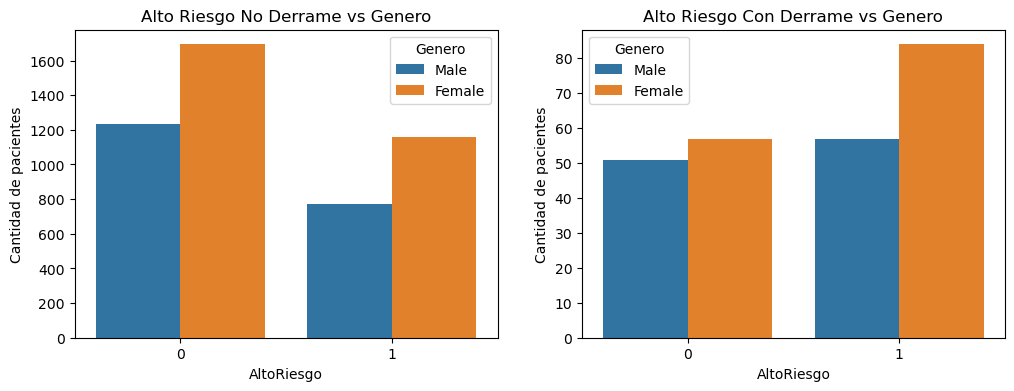

In [52]:
# Graficas de alto riesgo sin derrame vs genero

pandasDatos = df04.toPandas()

fig, matrix = plt.subplots(1,2, figsize=(12,4))

matrix[0].set_title("Alto Riesgo No Derrame vs Genero")
matrix[0].set_ylabel("Cantidad de pacientes")
matrix0 = sns.countplot(data = pandasDatos.loc[pandasDatos['Derrame'] == 0], x = 'AltoRiesgo', hue = 'Genero', ax = matrix[0])

matrix[1].set_title("Alto Riesgo Con Derrame vs Genero")
matrix[1].set_ylabel("Cantidad de pacientes")
matrix1 = sns.countplot(data = pandasDatos.loc[pandasDatos['Derrame'] == 1], x = 'AltoRiesgo', hue = 'Genero', ax = matrix[1])

## **Análisis:**

La gráfica compara la distribución de la regla entre las categorías de género conservadas en la exploración. Los resultados corresponden a la muestra posterior al filtro de Other; por tanto, no describen esa categoría. Los conteos deben interpretarse considerando los tamaños de cada grupo.

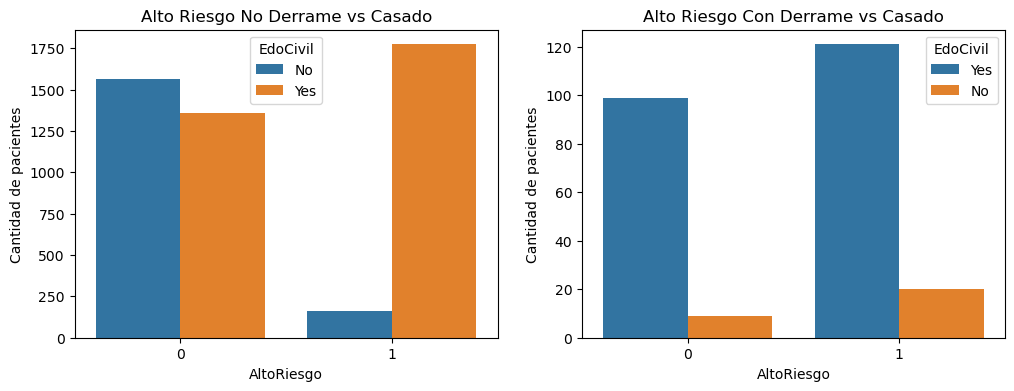

In [53]:
# Graficas de alto riesgo sin derrame vs casado

pandasDatos = df04.toPandas()

fig, matrix = plt.subplots(1,2, figsize=(12,4))

matrix[0].set_title("Alto Riesgo No Derrame vs Casado")
matrix[0].set_ylabel("Cantidad de pacientes")
matrix0 = sns.countplot(data = pandasDatos.loc[pandasDatos['Derrame'] == 0], x = 'AltoRiesgo', hue = 'EdoCivil', ax = matrix[0])

matrix[1].set_title("Alto Riesgo Con Derrame vs Casado")
matrix[1].set_ylabel("Cantidad de pacientes")
matrix1 = sns.countplot(data = pandasDatos.loc[pandasDatos['Derrame'] == 1], x = 'AltoRiesgo', hue = 'EdoCivil', ax = matrix[1])

## **Análisis:**

Esta variable procede de ever_married, por lo que indica haber estado casado alguna vez. Las diferencias pueden estar relacionadas con la composición por edad de los grupos. La gráfica no demuestra que el antecedente de matrimonio cause o prevenga un derrame.

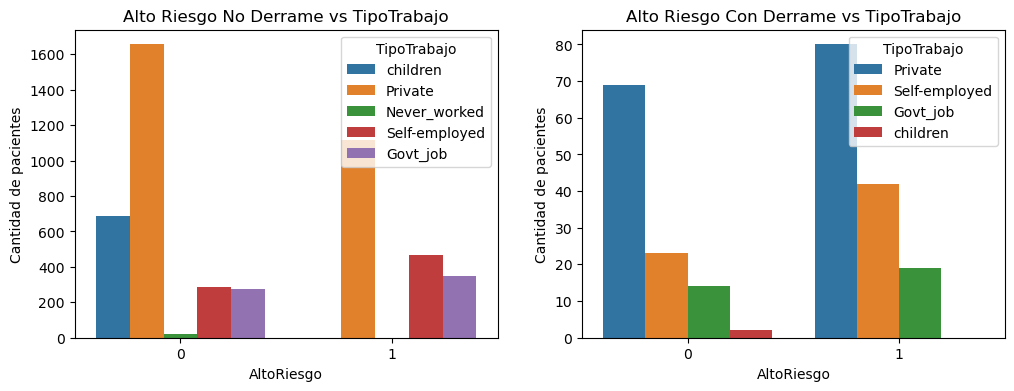

In [54]:
# Graficas de alto riesgo sin derrame vs tipo de trabajo

pandasDatos = df04.toPandas()

fig, matrix = plt.subplots(1,2, figsize=(12,4))

matrix[0].set_title("Alto Riesgo No Derrame vs TipoTrabajo")
matrix[0].set_ylabel("Cantidad de pacientes")
matrix0 = sns.countplot(data = pandasDatos.loc[pandasDatos['Derrame'] == 0], x = 'AltoRiesgo', hue = 'TipoTrabajo', ax = matrix[0])

matrix[1].set_title("Alto Riesgo Con Derrame vs TipoTrabajo")
matrix[1].set_ylabel("Cantidad de pacientes")
matrix1 = sns.countplot(data = pandasDatos.loc[pandasDatos['Derrame'] == 1], x = 'AltoRiesgo', hue = 'TipoTrabajo', ax = matrix[1])

## **Análisis:**

Las categorías combinan situaciones laborales y etapas de vida, como ocurre con children. Por ello, las diferencias observadas pueden reflejar diferencias de edad y tamaño de grupo. Los conteos permiten explorar la muestra, pero no comparar directamente probabilidades de derrame.

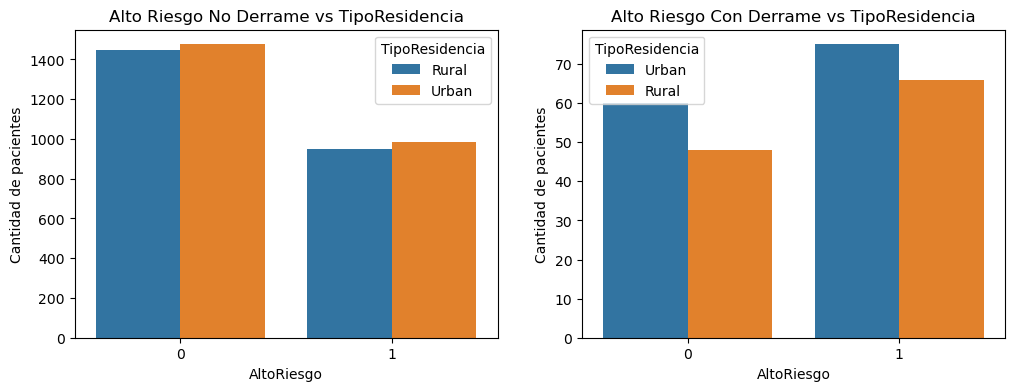

In [55]:
# Graficas de alto riesgo sin derrame vs TipoResidencia

pandasDatos = df04.toPandas()

fig, matrix = plt.subplots(1,2, figsize=(12,4))

matrix[0].set_title("Alto Riesgo No Derrame vs TipoResidencia")
matrix[0].set_ylabel("Cantidad de pacientes")
matrix0 = sns.countplot(data = pandasDatos.loc[pandasDatos['Derrame'] == 0], x = 'AltoRiesgo', hue = 'TipoResidencia', ax = matrix[0])

matrix[1].set_title("Alto Riesgo Con Derrame vs TipoResidencia")
matrix[1].set_ylabel("Cantidad de pacientes")
matrix1 = sns.countplot(data = pandasDatos.loc[pandasDatos['Derrame'] == 1], x = 'AltoRiesgo', hue = 'TipoResidencia', ax = matrix[1])

## **Análisis:**

Se presentan las combinaciones de residencia y la regla del ejercicio dentro de cada etiqueta. Para comparar proporciones entre residencia urbana y rural sería necesario utilizar como denominador el total de cada grupo. La gráfica no permite atribuir un efecto causal al lugar de residencia.

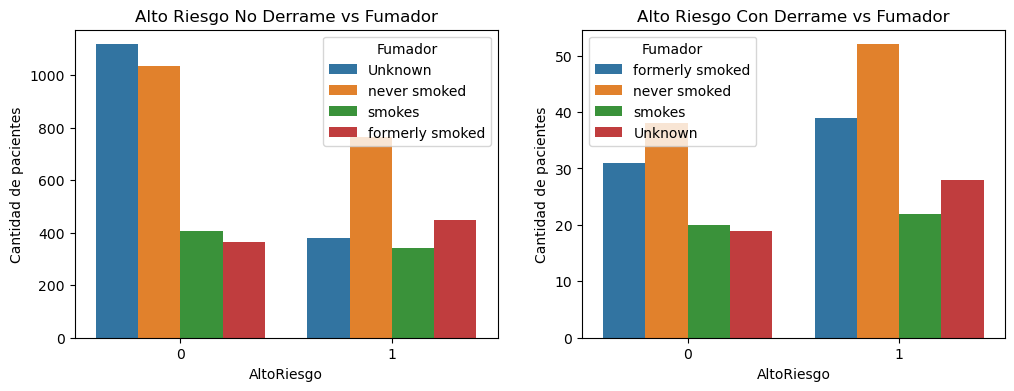

In [56]:
# Graficas de alto riesgo sin derrame vs Fumador

pandasDatos = df04.toPandas()

fig, matrix = plt.subplots(1,2, figsize=(12,4))

matrix[0].set_title("Alto Riesgo No Derrame vs Fumador")
matrix[0].set_ylabel("Cantidad de pacientes")
matrix0 = sns.countplot(data = pandasDatos.loc[pandasDatos['Derrame'] == 0], x = 'AltoRiesgo', hue = 'Fumador', ax = matrix[0])

matrix[1].set_title("Alto Riesgo Con Derrame vs Fumador")
matrix[1].set_ylabel("Cantidad de pacientes")
matrix1 = sns.countplot(data = pandasDatos.loc[pandasDatos['Derrame'] == 1], x = 'AltoRiesgo', hue = 'Fumador', ax = matrix[1])

## **Análisis:**

Se conserva Unknown como información desconocida y no se equipara con no haber fumado. Las barras describen cómo se distribuyen las categorías registradas. La presencia de información desconocida limita la interpretación del historial de consumo.

## Se requiere observar las categorías:
- La idea es cambiar cada categoría a un valor (ejemplo: Rural = 0, Urban = 1, ...)

In [57]:
df04.columns

['id',
 'Genero',
 'Edad',
 'Hipertension',
 'EnfCardiaca',
 'EdoCivil',
 'TipoTrabajo',
 'TipoResidencia',
 'NivelGlucosa',
 'IMC',
 'Fumador',
 'Derrame',
 'AltoRiesgo']

In [58]:
# Se revisa las categorias

df04.select('Genero').distinct().show()
df04.select('EdoCivil').distinct().show()
df04.select('TipoTrabajo').distinct().show()
df04.select('TipoResidencia').distinct().show()
df04.select('Fumador').distinct().show()

+------+
|Genero|
+------+
|Female|
|  Male|
+------+

+--------+
|EdoCivil|
+--------+
|      No|
|     Yes|
+--------+

+-------------+
|  TipoTrabajo|
+-------------+
| Never_worked|
|Self-employed|
|      Private|
|     children|
|     Govt_job|
+-------------+

+--------------+
|TipoResidencia|
+--------------+
|         Urban|
|         Rural|
+--------------+

+---------------+
|        Fumador|
+---------------+
|         smokes|
|        Unknown|
|   never smoked|
|formerly smoked|
+---------------+



In [59]:
#### Se requiere eliminar la columna ID porque no aporta información

df05 = df04.drop('id')

# Verificar
df05.columns

['Genero',
 'Edad',
 'Hipertension',
 'EnfCardiaca',
 'EdoCivil',
 'TipoTrabajo',
 'TipoResidencia',
 'NivelGlucosa',
 'IMC',
 'Fumador',
 'Derrame',
 'AltoRiesgo']

### Cambio de Variables en Categorías

In [60]:
## Columnas no categoricas

noCategoricas = ['Edad', 'Hipertension', 'EnfCardiaca', 'NivelGlucosa', 'IMC', 'Derrame', 'AltoRiesgo']

## Se hace un índice para las columnas (Categóricas y noCategóricas)
indice = [StringIndexer(inputCol = columna, outputCol = columna + "_IND").fit(df05)
         for columna in list(set(df05.columns) - set(noCategoricas))
         ]

In [61]:
# La idea es ahora generar un tratamiento en SECUENCIA o ETAPAS: PIPELINE
pipeBD = Pipeline(stages = indice)

# Se crea un nuevo objeto df para tener secuencia en las versiones
df06 = pipeBD.fit(df05).transform(df05)
df06.show(4)

+------+----+------------+-----------+--------+-------------+--------------+------------+-----+---------------+-------+----------+------------+----------+------------------+---------------+-----------+
|Genero|Edad|Hipertension|EnfCardiaca|EdoCivil|  TipoTrabajo|TipoResidencia|NivelGlucosa|  IMC|        Fumador|Derrame|AltoRiesgo|EdoCivil_IND|Genero_IND|TipoResidencia_IND|TipoTrabajo_IND|Fumador_IND|
+------+----+------------+-----------+--------+-------------+--------------+------------+-----+---------------+-------+----------+------------+----------+------------------+---------------+-----------+
|  Male|  67|           0|          1|     Yes|      Private|         Urban|      228.69| 36.6|formerly smoked|      1|         0|         0.0|       1.0|               0.0|            0.0|        2.0|
|Female|  61|           0|          0|     Yes|Self-employed|         Rural|      202.21|30.78|   never smoked|      1|         0|         0.0|       0.0|               1.0|            1.0|   

In [62]:
# Se borran las columnas categóricas
categoricas = ['Genero', 'EdoCivil', 'TipoTrabajo', 'TipoResidencia', 'Fumador']
df06 = df06.drop(*categoricas)
df06.show(4)

+----+------------+-----------+------------+-----+-------+----------+------------+----------+------------------+---------------+-----------+
|Edad|Hipertension|EnfCardiaca|NivelGlucosa|  IMC|Derrame|AltoRiesgo|EdoCivil_IND|Genero_IND|TipoResidencia_IND|TipoTrabajo_IND|Fumador_IND|
+----+------------+-----------+------------+-----+-------+----------+------------+----------+------------------+---------------+-----------+
|  67|           0|          1|      228.69| 36.6|      1|         0|         0.0|       1.0|               0.0|            0.0|        2.0|
|  61|           0|          0|      202.21|30.78|      1|         0|         0.0|       0.0|               1.0|            1.0|        0.0|
|  80|           0|          1|      105.92| 32.5|      1|         1|         0.0|       1.0|               1.0|            0.0|        0.0|
|  49|           0|          0|      171.23| 34.4|      1|         0|         0.0|       0.0|               0.0|            0.0|        3.0|
+----+-------

#### **División de datos en variables independientes y dependientes**

- Se usará el sistema 80/20%
- 80% para entrenamiento de los datos (el modelo sabe las respuestas)
- 20% para pruebas (el modelo no conoce las respuestas)
- Se calcula el porcentaje de valores positivos de la variable dependiente (ICTUS = 1)

In [63]:
## Se hace uso del vector ensamblador para el uso de los modelos

varIndependientes = VectorAssembler(inputCols=df06.drop('Derrame').columns, 
                                    outputCol='Independientes')

### Se aplica la transformación 
varIndependientes = varIndependientes.transform(df06).select('Independientes','Derrame')

# Se observa el resultado del vector
varIndependientes.show(5, False)

+--------------------------------------------------+-------+
|Independientes                                    |Derrame|
+--------------------------------------------------+-------+
|(11,[0,2,3,4,7,10],[67.0,1.0,228.69,36.6,1.0,2.0])|1      |
|(11,[0,3,4,8,9],[61.0,202.21,30.78,1.0,1.0])      |1      |
|[80.0,0.0,1.0,105.92,32.5,1.0,0.0,1.0,1.0,0.0,0.0]|1      |
|(11,[0,3,4,10],[49.0,171.23,34.4,3.0])            |1      |
|(11,[0,1,3,4,8,9],[79.0,1.0,174.12,24.0,1.0,1.0]) |1      |
+--------------------------------------------------+-------+
only showing top 5 rows



In [64]:
### dIVISIÓN DE CONJUNTOS DE ENTRENAMIENTO Y PRUEBA

df07 = varIndependientes.select(['Independientes', 'Derrame'])

### División por aleatoriedad
entrenamiento, prueba = df07.randomSplit([0.8,0.2])

In [65]:
### Revisión de porcentaje en conjunto de entrenamiento (Derrame = 1)

totalPacientes = df07.count()
totalPacDerrame = df07.select('Derrame').where("Derrame == 1").count()
totalEntrenamiento = entrenamiento.count()
pacientesEntreDerrame = entrenamiento.select('Derrame').where("Derrame == 1").count()

print(f"Total pacientes = {totalPacientes}")
print(f"Total pacientes con derrame = {totalPacDerrame}")
print(f"Total porcentaje con derrame = {round(totalPacDerrame/totalPacientes,2)}%")
print(f"Pacientes de entrenamiento = {totalEntrenamiento}")
print(f"Pacientes de entrenamiento de derrame = {pacientesEntreDerrame}")
print(f"Pacientes de entrenamiento de derrame (porcentaje) = {round(pacientesEntreDerrame/totalEntrenamiento, 2)}%")

Total pacientes = 5109
Total pacientes con derrame = 249
Total porcentaje con derrame = 0.05%
Pacientes de entrenamiento = 4064
Pacientes de entrenamiento de derrame = 203
Pacientes de entrenamiento de derrame (porcentaje) = 0.05%


### **Modelos MLlib**

- #### Logistic Regression
- #### Random Forest
- #### Decision Tree
- #### Support Vector
- #### Multilayer Perceptron Classifier

In [66]:
## Regresión logística
from pyspark.ml.classification import LogisticRegression

## Se instancia el modelo
RegLog = LogisticRegression(featuresCol = 'Independientes', labelCol = 'Derrame')

modeloRL = RegLog.fit(entrenamiento)

#Se obtienen predicciones
prediccionRL = modeloRL.transform(prueba)

## Se observan las predicciones
prediccionRL.show(5)

+--------------------+-------+--------------------+--------------------+----------+
|      Independientes|Derrame|       rawPrediction|         probability|prediction|
+--------------------+-------+--------------------+--------------------+----------+
|(11,[0,1,2,3,4],[...|      0|[1.85642445829244...|[0.86487964494857...|       0.0|
|(11,[0,1,2,3,4,5]...|      0|[0.80885054618555...|[0.69186450858828...|       0.0|
|(11,[0,1,2,3,4,10...|      0|[2.29313970178640...|[0.90830727609686...|       0.0|
|(11,[0,1,2,3,4,10...|      0|[0.95139280764824...|[0.72139519660924...|       0.0|
|(11,[0,1,3,4,5],[...|      0|[2.61993016733582...|[0.93213328888467...|       0.0|
+--------------------+-------+--------------------+--------------------+----------+
only showing top 5 rows



### **Evaluación ModeloRL**

In [67]:
### accuracy: Exactitud
accuracyRL = MulticlassClassificationEvaluator(labelCol='Derrame', 
                                               metricName='accuracy').evaluate(prediccionRL)

precisionRL = MulticlassClassificationEvaluator(labelCol='Derrame',
                                                metricName='weightedPrecision').evaluate(prediccionRL)

recallRL = MulticlassClassificationEvaluator(labelCol='Derrame',
                                            metricName='weightedRecall').evaluate(prediccionRL)

### se imprime
print(f"\t Exactitud en modelo RL")

	 Exactitud en modelo RL


## Preparación y diseño de la comparación

Se construye una comparación de cinco clasificadores utilizando las mismas observaciones de entrenamiento y prueba.

Se retoma df01, que contiene las columnas originales renombradas, antes de la imputación exploratoria. Se conserva la categoría Other y la información de tabaquismo registrada como Unknown.

Las decisiones de preparación son:
- Conservar la edad como número decimal.
- Excluir id de las características predictoras: se utiliza únicamente para verificar identificadores y separar registros.
- Utilizar Derrame exclusivamente como etiqueta.
- Excluir la regla académica AltoRiesgo.
- Completar las variables continuas mediante medianas aprendidas con entrenamiento.
- Añadir un indicador que identifique los registros cuyo IMC estaba ausente.
- Codificar las categorías mediante StringIndexer y OneHotEncoder, evitando asignarles un orden numérico artificial.
- Estandarizar las variables continuas utilizando parámetros aprendidos con entrenamiento.
- Mantener las proporciones originales de las clases, sin remuestreo, para establecer una primera comparación común.
Se utiliza aproximadamente un 80 % de cada clase para entrenamiento y un 20 % para prueba. La separación es reproducible y permite conservar ambas clases en los dos conjuntos.

In [68]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from IPython.display import display, Markdown

from pyspark.sql import functions as F, Window
from pyspark.ml import Pipeline

from pyspark.ml.feature import (
    Imputer,
    StringIndexer,
    OneHotEncoder,
    VectorAssembler,
    StandardScaler
)

from pyspark.ml.classification import (
    LogisticRegression,
    DecisionTreeClassifier,
    RandomForestClassifier,
    LinearSVC,
    MultilayerPerceptronClassifier
)

from pyspark.ml.evaluation import BinaryClassificationEvaluator
from pyspark.ml.functions import vector_to_array

# Se utiliza para reproducir la separación y los modelos aleatorios.
SEMILLA = 1255

continuas = [
    "Edad",
    "NivelGlucosa",
    "IMC"
]

binarias = [
    "Hipertension",
    "EnfCardiaca"
]

categoricas = [
    "Genero",
    "EdoCivil",
    "TipoTrabajo",
    "TipoResidencia",
    "Fumador"
]

In [69]:
# Se parte de los datos anteriores a la imputación exploratoria
base_ml = df01.select(
    "id",
    *continuas,
    *binarias,
    *categoricas,
    "Derrame"
)

# Se conservan decimales de edad
for columna in continuas + binarias + ["Derrame"]:
    base_ml = base_ml.withColumn(
        columna,
        F.expr(f"try_cast({columna} as double)")
    )

# Se trata NaN e infinitos como información faltante sin eliminar valores extremos
for columna in continuas:
    base_ml = base_ml.withColumn(
        columna,
        F.when(
            F.isnan(F.col(columna))
            | (F.abs(F.col(columna)) == float("inf")),
            F.lit(None).cast("double")
        ).otherwise(F.col(columna))
    )

# Se conserva Unknown y las demás categorías originales, pasando solo null y texto vacío a SIN_DATO
for columna in categoricas:
    base_ml = base_ml.withColumn(
        columna,
        F.when(
            F.col(columna).isNull()
            | (F.trim(F.col(columna)) == ""),
            F.lit("SIN_DATO")
        ).otherwise(F.trim(F.col(columna)))
    )

# Un modelo supervisado necesita una etiqueta conocida.
# No se imputa la respuesta ni se convierte una etiqueta ausente en cero.
n_antes = base_ml.count()

base_ml = (
    base_ml
    .filter(F.col("Derrame").isin(0.0, 1.0))
    .cache()
)

n_despues = base_ml.count()

print("Filas originales:", n_antes)
print("Filas con etiqueta válida:", n_despues)
print(
    "Excluidas por etiqueta ausente o distinta de 0/1:",
    n_antes - n_despues
)

# Se vericican identificadores antes de dividir
if base_ml.filter(F.col("id").isNull()).limit(1).count():
    raise ValueError(
        "Hay identificadores vacíos: revísalos antes de dividir."
    )

ids_repetidos = (
    base_ml
    .groupBy("id")
    .count()
    .filter(F.col("count") > 1)
)

if ids_repetidos.limit(1).count():
    raise ValueError(
        "Hay IDs repetidos: revisa si son duplicados "
        "o personas con varias filas."
    )

# Las variables binarias deben conservar su significado 0/1
for columna in binarias:
    invalidos = base_ml.filter(
        F.col(columna).isNull()
        | ~F.col(columna).isin(0.0, 1.0)
    ).limit(1).count()

    if invalidos:
        raise ValueError(
            f"Revisa {columna}: sus valores deben ser 0 o 1."
        )

# Se crea el indicador ANTES de completar el IMC
base_ml = base_ml.withColumn(
    "IMC_faltante",
    F.col("IMC").isNull().cast("double")
)

print("Distribución de la etiqueta:")
base_ml.groupBy("Derrame").count().orderBy("Derrame").show()

print("Faltantes en variables continuas:")
base_ml.select([
    F.sum(
        F.col(c).isNull().cast("long")
    ).alias(c)
    for c in continuas
]).show()

Filas originales: 5110
Filas con etiqueta válida: 5110
Excluidas por etiqueta ausente o distinta de 0/1: 0
Distribución de la etiqueta:
+-------+-----+
|Derrame|count|
+-------+-----+
|    0.0| 4861|
|    1.0|  249|
+-------+-----+

Faltantes en variables continuas:
+----+------------+---+
|Edad|NivelGlucosa|IMC|
+----+------------+---+
|   0|           0|201|
+----+------------+---+



In [70]:
# Se comprueba que existen suficientes registros de ambas clases
conteos_clase = {
    int(fila["Derrame"]): fila["count"]
    for fila in (
        base_ml.groupBy("Derrame").count().collect()
    )
}

if (
    set(conteos_clase) != {0, 1}
    or min(conteos_clase.values()) < 2
):
    raise ValueError(
        "Se necesitan al menos dos registros de cada clase."
    )

# Se trabaja por separado dentro de cada clase
ventana_clase = Window.partitionBy("Derrame")

# Se construye un orden pseudoaleatorio reproducible
# El ID sirve para repartir y desempatar, no para predecir
ventana_orden = ventana_clase.orderBy(
    F.xxhash64("id", F.lit(SEMILLA)),
    F.col("id")
)

particion = (
    base_ml

    # Se ennumeran los registros dentro de cada clase
    .withColumn(
        "_posicion",
        F.row_number().over(ventana_orden)
    )

    # Se cuenta cuántos registros tiene cada clase
    .withColumn(
        "_n_clase",
        F.count("*").over(ventana_clase)
    )

    # Se destina aproximadamente el 80 % de cada clase a entrenamiento
    .withColumn(
        "conjunto",
        F.when(
            F.col("_posicion")
            <= F.floor(0.8 * F.col("_n_clase")),
            F.lit("Entrenamiento")
        ).otherwise(F.lit("Prueba"))
    )

    .drop("_posicion", "_n_clase")
    .cache()
)

# Se materializa la partición para reutilizarla.
particion.count()

entrenamiento_raw = (
    particion
    .filter(F.col("conjunto") == "Entrenamiento")
    .drop("conjunto")
)

prueba_raw = (
    particion
    .filter(F.col("conjunto") == "Prueba")
    .drop("conjunto")
)

# Se muestra la composición de cada conjunto.
distribucion = (
    particion
    .groupBy("conjunto", "Derrame")
    .count()
    .withColumn(
        "porcentaje",
        F.round(
            100.0 * F.col("count")
            / F.sum("count").over(
                Window.partitionBy("conjunto")
            ),
            2
        )
    )
)

distribucion.orderBy(
    "conjunto",
    "Derrame"
).show()

# Se verifica que no se comparte un ID entre los conjuntos
ids_compartidos = (
    entrenamiento_raw.select("id")
    .join(prueba_raw.select("id"), "id")
)

if ids_compartidos.limit(1).count():
    raise ValueError(
        "Un mismo ID aparece en entrenamiento y prueba."
    )

+-------------+-------+-----+----------+
|     conjunto|Derrame|count|porcentaje|
+-------------+-------+-----+----------+
|Entrenamiento|    0.0| 3888|     95.13|
|Entrenamiento|    1.0|  199|      4.87|
|       Prueba|    0.0|  973|     95.11|
|       Prueba|    1.0|   50|      4.89|
+-------------+-------+-----+----------+



In [71]:
# Se completan variables continuas con medianas de entrenamiento.
imputador = Imputer(
    strategy="median",
    inputCols=continuas,
    outputCols=[c + "_imp" for c in continuas]
)

# Se convierten textos a índices
indexadores = [
    StringIndexer(
        inputCol=c,
        outputCol=c + "_idx",
        handleInvalid="keep"
    )
    for c in categoricas
]

# Se convierten los índices a indicadores
codificador = OneHotEncoder(
    inputCols=[c + "_idx" for c in categoricas],
    outputCols=[c + "_ohe" for c in categoricas],
    handleInvalid="keep",
    dropLast=False
)

# Se reunen las variables continuas ya imputadas
vector_continuo = VectorAssembler(
    inputCols=[c + "_imp" for c in continuas],
    outputCol="continuas_vector"
)

# Se estandarizan las continuas: centrar y dividir por su desviación
escalador = StandardScaler(
    inputCol="continuas_vector",
    outputCol="continuas_escaladas",
    withMean=True,
    withStd=True
)

# Se construye el vector final sin incluir id, Derrame ni la regla AltoRiesgo
ensamblador = VectorAssembler(
    inputCols=(
        ["continuas_escaladas"]
        + binarias
        + ["IMC_faltante"]
        + [c + "_ohe" for c in categoricas]
    ),
    outputCol="features"
)

# Se establece orden de ejecución
preparacion = Pipeline(
    stages=(
        [imputador]
        + indexadores
        + [
            codificador,
            vector_continuo,
            escalador,
            ensamblador
        ]
    )
)

# Se aprenden medianas, categorías y escalas con entrenamiento
modelo_preparacion = preparacion.fit(entrenamiento_raw)

# Se aplica la misma preparación a ambos conjuntos.
entrenamiento = (
    modelo_preparacion
    .transform(entrenamiento_raw)
    .select("id", "Derrame", "features")
    .cache()
)

prueba = (
    modelo_preparacion
    .transform(prueba_raw)
    .select("id", "Derrame", "features")
    .cache()
)

print("Entrenamiento:", entrenamiento.count())
print("Prueba:", prueba.count())

print("Medianas aprendidas con entrenamiento:")
modelo_preparacion.stages[0].surrogateDF.show()

# La dimensión depende de las categorías encontradas
n_features = len(entrenamiento.first()["features"])

print("Tamaño del vector de características:", n_features)

entrenamiento.show(5, truncate=80)

Entrenamiento: 4087
Prueba: 1023
Medianas aprendidas con entrenamiento:
+----+------------+----+
|Edad|NivelGlucosa| IMC|
+----+------------+----+
|45.0|        92.0|28.1|
+----+------------+----+

Tamaño del vector de características: 32
+-----+-------+--------------------------------------------------------------------------------+
|   id|Derrame|                                                                        features|
+-----+-------+--------------------------------------------------------------------------------+
|13323|    0.0|(32,[0,1,2,7,12,18,22,27],[-1.8006551610659034,-0.12066618225077198,-1.427202...|
|23240|    0.0|(32,[0,1,2,6,11,15,23,26],[-0.10716448596183055,-0.32821495843009674,0.076071...|
|63026|    0.0|(32,[0,1,2,7,12,18,23,27],[-1.7115240729025312,-0.5946241282772087,-1.8193606...|
|13375|    0.0|(32,[0,1,2,7,11,15,22,26],[1.4526295568971839,1.8884938224989234,0.2721503843...|
|70374|    0.0|(32,[0,1,2,6,11,15,23,29],[-0.5528199267786919,0.3515347370990144,1

## Selección de los modelos

Se comparan cinco técnicas de clasificación disponibles en MLlib:

- Regresión logística: proporciona una referencia de clasificación lineal regularizada para una etiqueta binaria
- Árbol de decisión: permite representar relaciones no lineales mediante reglas de partición
- Bosque aleatorio: combina varios árboles para estudiar relaciones e interacciones con menor dependencia de un único árbol
- SVM lineal: aporta una alternativa lineal basada en un margen de separación entre clases
- Perceptrón multicapa: permite comparar una red neuronal con las técnicas lineales y los árboles

Se utilizan configuraciones iniciales moderadas para establecer una comparación reproducible. Los parámetros no se presentan como valores óptimos obtenidos mediante una búsqueda exhaustiva.

Todos los modelos reciben los mismos datos preparados y se evalúan sobre el mismo conjunto de prueba. Se conservan sus umbrales predeterminados.

In [72]:
algoritmos = {
    "Regresión logística": LogisticRegression(
        featuresCol="features",
        labelCol="Derrame",
        maxIter=100,
        regParam=0.01,
        elasticNetParam=0.0
    ),

    "Árbol de decisión": DecisionTreeClassifier(
        featuresCol="features",
        labelCol="Derrame",
        maxDepth=5,
        minInstancesPerNode=10,
        seed=SEMILLA
    ),

    "Bosque aleatorio": RandomForestClassifier(
        featuresCol="features",
        labelCol="Derrame",
        numTrees=50,
        maxDepth=5,
        minInstancesPerNode=5,
        seed=SEMILLA
    ),

    "SVM lineal": LinearSVC(
        featuresCol="features",
        labelCol="Derrame",
        maxIter=100,
        regParam=0.1
    ),

    "Perceptrón multicapa": MultilayerPerceptronClassifier(
        featuresCol="features",
        labelCol="Derrame",

        # Entrada: tamaño real del vector.
        # Capa oculta: 16 neuronas.
        # Salida: dos clases.
        layers=[n_features, 16, 2],

        maxIter=100,
        seed=SEMILLA,
        blockSize=64
    )
}

## Criterios de evaluación

El conjunto contiene muchos más registros negativos que positivos. Por ello, la exactitud se acompaña de métricas específicas de la clase Derrame = 1.

- Exactitud: proporción total de clasificaciones correctas
- Sensibilidad: proporción de positivos reales que el modelo identifica
- Precisión positiva: proporción de positivos predichos que realmente pertenecen a la clase positiva
- F1 positivo: media armónica de precisión positiva y sensibilidad
- Especificidad: proporción de negativos reales correctamente identificados
- Exactitud balanceada: promedio de sensibilidad y especificidad
- ROC-AUC: capacidad de ordenar positivos por encima de negativos considerando distintos umbrales
- PR-AUC: área bajo la curva precisión–sensibilidad, útil para complementar el análisis de una clase positiva poco frecuente

También se presentan matrices de confusión con verdaderos positivos, verdaderos negativos, falsos positivos y falsos negativos.

Si un modelo no predice ningún positivo, su precisión positiva se reporta como cero por convenio y se señala expresamente esta situación.

La comparación utiliza una sola partición de entrenamiento y prueba. El mejor resultado observado en esta partición no constituye una demostración de superioridad general ni una validación externa.

In [73]:
def evaluar_modelo(nombre, predicciones):
    """
    Calcular métricas sobre prueba.

    Clase positiva: Derrame = 1.
    """

    # La tabla agregada tiene como máximo cuatro combinaciones.
    conteos = {
        (
            int(fila["Derrame"]),
            int(fila["prediction"])
        ): int(fila["count"])

        for fila in (
            predicciones
            .groupBy("Derrame", "prediction")
            .count()
            .collect()
        )
    }

    vn = conteos.get((0, 0), 0)
    fp = conteos.get((0, 1), 0)
    fn = conteos.get((1, 0), 0)
    vp = conteos.get((1, 1), 0)

    total = vn + fp + fn + vp

    # Se evitan divisiones entre 0
    precision_1 = vp / (vp + fp) if vp + fp else 0.0
    sensibilidad = vp / (vp + fn) if vp + fn else 0.0
    especificidad = vn / (vn + fp) if vn + fp else 0.0

    f1_1 = (
        2 * precision_1 * sensibilidad
        / (precision_1 + sensibilidad)

        if precision_1 + sensibilidad else 0.0
    )

    # score debe aumentar cuando aumenta el apoyo a la clase 1
    # numBins=0 evita reducir la curva mediante agrupación en bins
    evaluador = BinaryClassificationEvaluator(
        labelCol="Derrame",
        rawPredictionCol="score",
        numBins=0
    )

    auc_roc = evaluador.evaluate(
        predicciones,
        {evaluador.metricName: "areaUnderROC"}
    )

    auc_pr = evaluador.evaluate(
        predicciones,
        {evaluador.metricName: "areaUnderPR"}
    )

    return {
        "modelo": nombre,
        "exactitud": (vp + vn) / total,
        "precision_1": precision_1,
        "sensibilidad": sensibilidad,
        "especificidad": especificidad,
        "f1_1": f1_1,
        "exactitud_balanceada": (
            sensibilidad + especificidad
        ) / 2,
        "auc_roc": auc_roc,
        "auc_pr": auc_pr,
        "VP": vp,
        "VN": vn,
        "FP": fp,
        "FN": fn
    }

In [74]:
modelos = {}
predicciones_modelos = {}
metricas = []

for nombre, algoritmo in algoritmos.items():
    print("Entrenando:", nombre)

    # Se aprende únicamente con entrenamiento
    modelo = algoritmo.fit(entrenamiento)

    # Se generan predicciones únicamente sobre prueba
    pred = modelo.transform(prueba)

    # LR, árboles, bosque y MLP producen probability.
    # LinearSVC utiliza un margen en rawPrediction.
    columna_score = (
        "probability"
        if "probability" in pred.columns
        else "rawPrediction"
    )

    pred = (
        pred
        .withColumn(
            "score",
            vector_to_array(
                F.col(columna_score)
            )[1]
        )
        .select(
            "id",
            "Derrame",
            "prediction",
            "score"
        )
        .cache()
    )

    resultado = evaluar_modelo(nombre, pred)

    modelos[nombre] = modelo
    predicciones_modelos[nombre] = pred
    metricas.append(resultado)

    print(
        f"  PR-AUC={resultado['auc_pr']:.4f} | "
        f"Sensibilidad={resultado['sensibilidad']:.4f} | "
        f"F1 clase 1={resultado['f1_1']:.4f}"
    )

# Se convierten filas de métricas a pandas
comparacion = (
    pd.DataFrame(metricas)
    .sort_values(
        ["auc_pr", "sensibilidad"],
        ascending=False
    )
    .reset_index(drop=True)
)

columnas_metricas = [
    "modelo",
    "auc_pr",
    "auc_roc",
    "sensibilidad",
    "precision_1",
    "f1_1",
    "especificidad",
    "exactitud",
    "exactitud_balanceada"
]

display(
    comparacion[columnas_metricas].round(4)
)

Entrenando: Regresión logística
  PR-AUC=0.2135 | Sensibilidad=0.0000 | F1 clase 1=0.0000
Entrenando: Árbol de decisión
  PR-AUC=0.0489 | Sensibilidad=0.0000 | F1 clase 1=0.0000
Entrenando: Bosque aleatorio
  PR-AUC=0.2296 | Sensibilidad=0.0000 | F1 clase 1=0.0000
Entrenando: SVM lineal


  PR-AUC=0.0861 | Sensibilidad=0.0000 | F1 clase 1=0.0000
Entrenando: Perceptrón multicapa


  PR-AUC=0.1823 | Sensibilidad=0.1200 | F1 clase 1=0.1690


,modelo,auc_pr,auc_roc,sensibilidad,precision_1,f1_1,especificidad,exactitud,exactitud_balanceada
0,Bosque aleatorio,0.2296,0.8434,0.00,0.0000,0.000,1.0000,0.9511,0.5000
1,Regresión logística,0.2135,0.8521,0.00,0.0000,0.000,1.0000,0.9511,0.5000
2,Perceptrón multicapa,0.1823,0.7992,0.12,0.2857,0.169,0.9846,0.9423,0.5523
3,SVM lineal,0.0861,0.6006,0.00,0.0000,0.000,1.0000,0.9511,0.5000
4,Árbol de decisión,0.0489,0.5000,0.00,0.0000,0.000,1.0000,0.9511,0.5000


In [75]:
conteos_prueba = {
    int(fila["Derrame"]): int(fila["count"])
    for fila in (
        prueba.groupBy("Derrame").count().collect()
    )
}

n_positivos = conteos_prueba[1]
n_negativos = conteos_prueba[0]
n_prueba = n_positivos + n_negativos

exactitud_base = n_negativos / n_prueba

print("Referencia que siempre predice Derrame = 0:")
print(f"Exactitud: {100 * exactitud_base:.2f} %")
print("Sensibilidad: 0 %")
print("Exactitud balanceada: 50 %")
print(
    f"Casos positivos omitidos: "
    f"{n_positivos} de {n_positivos}"
)

# Se señalan modelos que no identificaron ningún registro como positivo
for fila in metricas:
    positivos_predichos = fila["VP"] + fila["FP"]

    if positivos_predichos == 0:
        print(
            f"AVISO: {fila['modelo']} no predijo ningún positivo. "
            "Su precisión positiva se informa como 0 por convenio."
        )

Referencia que siempre predice Derrame = 0:
Exactitud: 95.11 %
Sensibilidad: 0 %
Exactitud balanceada: 50 %
Casos positivos omitidos: 50 de 50
AVISO: Regresión logística no predijo ningún positivo. Su precisión positiva se informa como 0 por convenio.
AVISO: Árbol de decisión no predijo ningún positivo. Su precisión positiva se informa como 0 por convenio.
AVISO: Bosque aleatorio no predijo ningún positivo. Su precisión positiva se informa como 0 por convenio.
AVISO: SVM lineal no predijo ningún positivo. Su precisión positiva se informa como 0 por convenio.


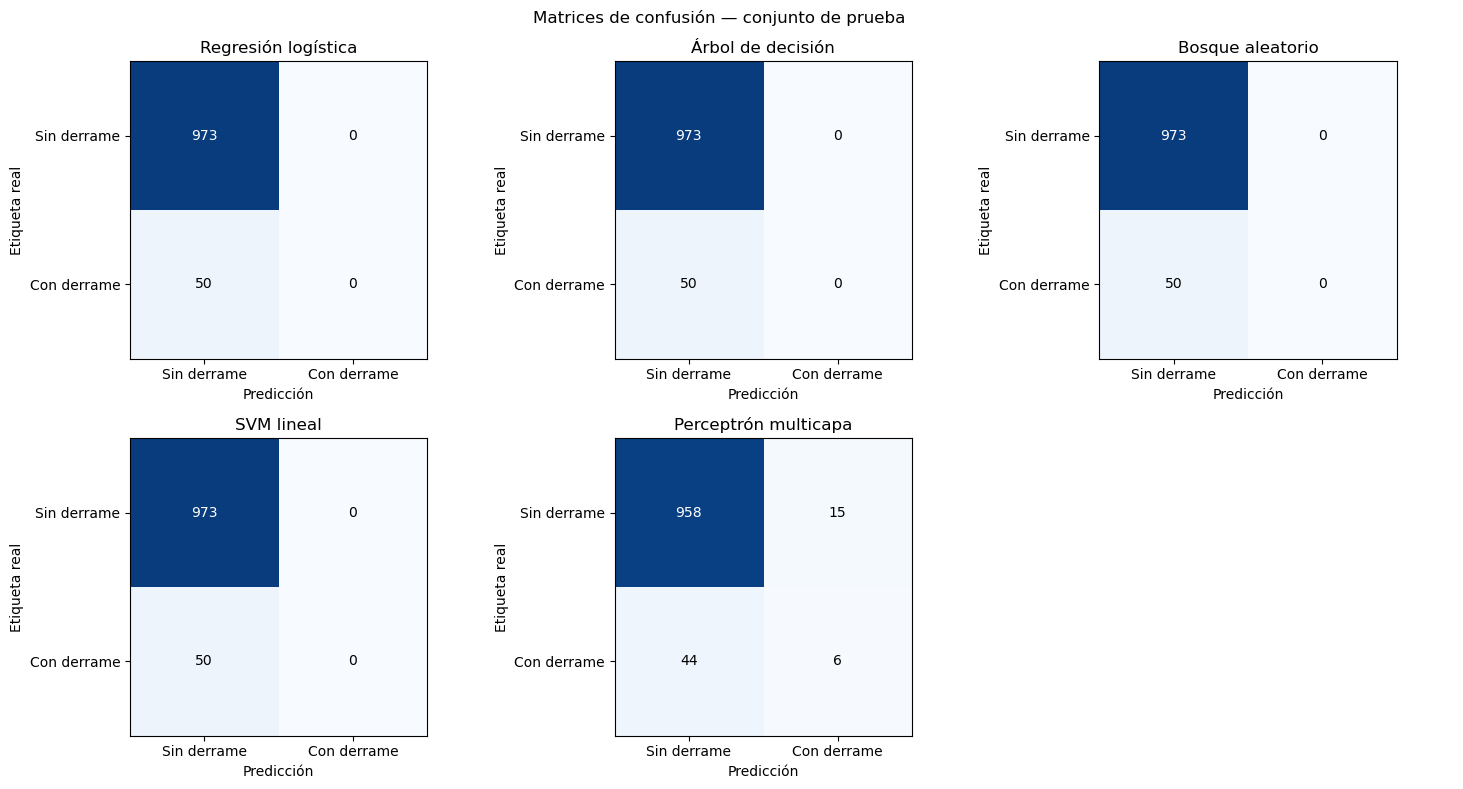

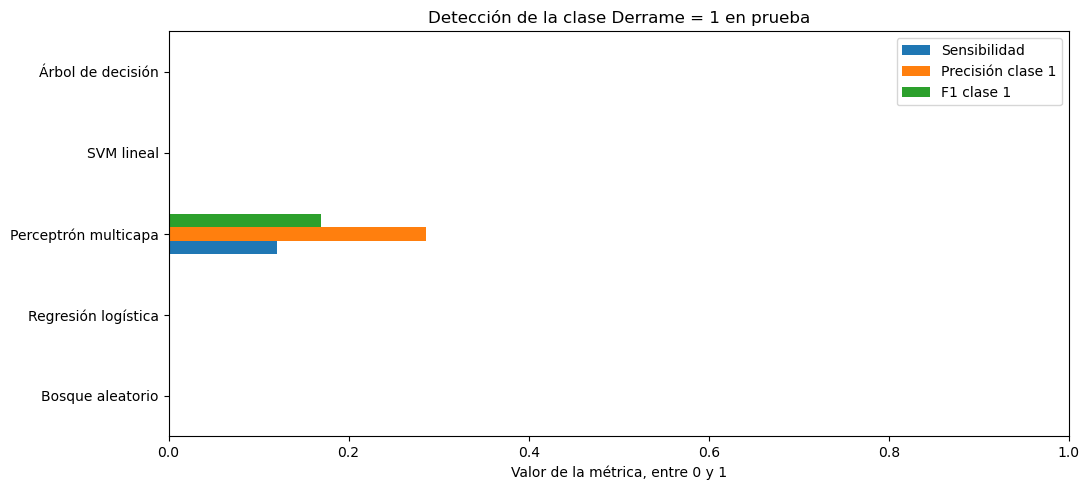

In [76]:
# Se hace una matriz por modelo
fig, ejes = plt.subplots(
    2,
    3,
    figsize=(15, 8)
)

for ax, fila in zip(ejes.flat, metricas):
    matriz = np.array([
        [fila["VN"], fila["FP"]],
        [fila["FN"], fila["VP"]]
    ])

    # Se establece la misma escala de colores
    ax.imshow(
        matriz,
        cmap="Blues",
        vmin=0,
        vmax=n_prueba
    )

    # Se escriben los conteos dentro de cada celda
    for i in range(2):
        for j in range(2):
            ax.text(
                j,
                i,
                str(matriz[i, j]),
                ha="center",
                va="center",
                color=(
                    "white"
                    if matriz[i, j] > n_prueba / 2
                    else "black"
                )
            )

    ax.set_title(fila["modelo"])

    ax.set_xticks(
        [0, 1],
        ["Sin derrame", "Con derrame"]
    )

    ax.set_yticks(
        [0, 1],
        ["Sin derrame", "Con derrame"]
    )

    ax.set_xlabel("Predicción")
    ax.set_ylabel("Etiqueta real")

# Se establecen los 6 espacios para los 5 modelos
ejes.flat[-1].axis("off")

fig.suptitle(
    "Matrices de confusión — conjunto de prueba"
)

fig.tight_layout()
plt.show()

# Se comparan métricas
ax = (
    comparacion
    .set_index("modelo")[
        ["sensibilidad", "precision_1", "f1_1"]
    ]
    .plot.barh(figsize=(11, 5))
)

ax.set_xlim(0, 1)
ax.set_xlabel("Valor de la métrica, entre 0 y 1")
ax.set_ylabel("")
ax.set_title(
    "Detección de la clase Derrame = 1 en prueba"
)

ax.legend([
    "Sensibilidad",
    "Precisión clase 1",
    "F1 clase 1"
])

plt.tight_layout()
plt.show()

## Análisis de resultados de los modelos

### 1. Datos utilizados y preparación

El bloque final de modelado utilizó **5.110 registros**, de los cuales **4.861 corresponden a `Derrame = 0`** y **249 a `Derrame = 1`**. Todos contaban con una etiqueta válida, por lo que no fue necesario excluir observaciones por ausencia o invalidez de la respuesta.

La separación estratificada produjo los siguientes conjuntos:

| Conjunto | Sin derrame | Con derrame | Total | Porcentaje con derrame |
|---|---:|---:|---:|---:|
| Entrenamiento | 3.888 | 199 | 4.087 | 4,87 % |
| Prueba | 973 | 50 | 1.023 | 4,89 % |

Las proporciones son semejantes entre los conjuntos, lo que permite evaluar los modelos conservando aproximadamente la composición original de las clases.

Se identificaron **201 valores faltantes de IMC**, mientras que edad y nivel de glucosa no presentaron faltantes en esta revisión. La preparación aprendió las siguientes medianas utilizando exclusivamente entrenamiento: **45 años**, **92,0 para nivel de glucosa** y **28,1 para IMC**. En esta ejecución, el reemplazo de faltantes fue necesario para IMC.

La codificación de categorías, el indicador de IMC faltante y el ensamblado generaron un vector de **32 componentes**. Este número corresponde a la representación transformada de las variables, no a 32 atributos originales del archivo.

### 2. Comparación general

Los cinco modelos se evaluaron sobre los mismos **1.023 registros de prueba**.

| Modelo | PR-AUC | ROC-AUC | Sensibilidad | Precisión positiva | F1 positivo | Exactitud | Exactitud balanceada |
|---|---:|---:|---:|---:|---:|---:|---:|
| Bosque aleatorio | **0,2296** | 0,8434 | 0,00 % | 0,00 %* | 0,0000 | 95,11 % | 50,00 % |
| Regresión logística | 0,2135 | **0,8521** | 0,00 % | 0,00 %* | 0,0000 | 95,11 % | 50,00 % |
| Perceptrón multicapa | 0,1823 | 0,7992 | **12,00 %** | **28,57 %** | **0,1690** | 94,23 % | **55,23 %** |
| SVM lineal | 0,0861 | 0,6006 | 0,00 % | 0,00 %* | 0,0000 | 95,11 % | 50,00 % |
| Árbol de decisión | 0,0489 | 0,5000 | 0,00 % | 0,00 %* | 0,0000 | 95,11 % | 50,00 % |

*Cuando un modelo no produce ninguna predicción positiva, la precisión positiva no tiene denominador. El procedimiento la informa como cero por convenio.*

Los resultados muestran que **no existe un único modelo superior en todas las métricas**: el bosque obtuvo la mayor PR-AUC, la regresión logística la mayor ROC-AUC y el perceptrón la mayor sensibilidad con los umbrales utilizados.

### 3. Exactitud y desbalance de clases

Un clasificador que siempre predice `Derrame = 0` acierta los **973 negativos** del conjunto de prueba y omite sus **50 positivos**. Su exactitud es:

**973 / 1.023 × 100 = 95,11 %.**

La regresión logística, el árbol, el bosque y la SVM produjeron precisamente ese comportamiento en sus predicciones finales: clasificaron todos los registros como negativos.

Por tanto, su exactitud del **95,11 % no representa una identificación satisfactoria de la clase positiva**. Su sensibilidad fue cero y su exactitud balanceada fue del 50 %, porque reconocieron todos los negativos y ninguno de los positivos.

El desbalance proporciona un contexto importante para interpretar este resultado, aunque no permite atribuir por sí solo la conducta de cada algoritmo a una única causa.

### 4. Bosque aleatorio

El bosque alcanzó la **mayor PR-AUC observada: 0,2296**, junto con una ROC-AUC de **0,8434**. Estas métricas muestran capacidad para ordenar los registros mediante sus puntuaciones.

Sin embargo, con el umbral predeterminado no clasificó ningún registro como positivo. Su matriz contiene **973 verdaderos negativos, 50 falsos negativos y cero verdaderos positivos**.

La diferencia entre las áreas y la sensibilidad no es una contradicción: las áreas consideran distintos umbrales, mientras que la matriz describe las decisiones producidas con el umbral utilizado.

En consecuencia, el bosque obtuvo el mejor resultado de esta comparación en PR-AUC, pero **no fue un detector efectivo de positivos con su configuración de decisión actual**.

### 5. Regresión logística

La regresión logística obtuvo la **mayor ROC-AUC: 0,8521**, y la segunda mayor PR-AUC: **0,2135**.

Estos resultados indican una capacidad de ordenación superior a la observada para la SVM y el árbol en esta partición. Sin embargo, ninguna puntuación produjo una clasificación positiva con el umbral utilizado.

Por ello, una ROC-AUC de 0,8521 **no significa que se haya detectado el 85,21 % de los registros con derrame**. La sensibilidad observada fue del 0 %.

El resultado permite diferenciar la capacidad de asignar puntuaciones relativas de la capacidad de identificar positivos mediante una regla de decisión concreta.

### 6. Perceptrón multicapa

El perceptrón fue el **único modelo que produjo predicciones positivas**. Su matriz de confusión fue:

| Etiqueta real / Predicción | Sin derrame | Con derrame |
|---|---:|---:|
| Sin derrame | 958 | 15 |
| Con derrame | 44 | 6 |

Identificó **6 de los 50 positivos reales**, equivalente a una **sensibilidad del 12 %**. No obstante, omitió **44 casos**, es decir, el **88 % de los positivos de prueba**.

Produjo **21 predicciones positivas**: seis correctas y quince falsas alarmas. Por ello, su precisión positiva fue del **28,57 %**. Esta proporción tiene un denominador diferente al de la sensibilidad: seis aciertos entre 21 predicciones positivas, frente a seis aciertos entre 50 positivos reales.

Su F1 positivo fue **0,1690**, su especificidad **98,46 %** y su exactitud balanceada **55,23 %**.

Aunque logró detectar algunos positivos, el número de casos omitidos sigue siendo elevado. El resultado representa una mejora de detección frente a los otros modelos con los umbrales utilizados, pero no demuestra una capacidad suficiente para un uso clínico.

Su exactitud fue **94,23 %**, aproximadamente **0,88 puntos porcentuales menor** que la referencia siempre negativa. Esto sucede porque recuperó seis positivos, pero introdujo quince falsos positivos: en total obtuvo nueve clasificaciones correctas menos. El ejemplo evidencia que mejorar la sensibilidad puede implicar un costo en falsas alarmas y exactitud global.

### 7. SVM lineal y árbol de decisión

La SVM obtuvo una ROC-AUC de **0,6006** y una PR-AUC de **0,0861**, inferiores a las de regresión logística, bosque y perceptrón. Además, no identificó positivos con su regla de decisión predeterminada.

El árbol obtuvo una ROC-AUC de **0,5000** y una PR-AUC de **0,0489**, esta última coincidente, al redondear, con la proporción positiva del conjunto de prueba. En esta configuración y partición no mostró una capacidad discriminativa útil y tampoco identificó positivos.

Estos resultados describen los modelos entrenados con los parámetros seleccionados. No demuestran que estas familias de algoritmos sean incapaces de obtener otros resultados con preparaciones o configuraciones diferentes.

### 8. Interpretación de las gráficas

Las matrices de confusión permiten observar que los cuatro modelos con mayor exactitud concentran sus predicciones en la clase negativa. El número de verdaderos negativos domina visualmente, pero la fila correspondiente a los positivos revela que todos fueron omitidos.

La gráfica de sensibilidad, precisión y F1 muestra valores distintos de cero únicamente para el perceptrón. La ausencia de barras en los otros modelos corresponde a métricas iguales a cero, no a un error de visualización.

Las gráficas complementan la tabla: permiten identificar comportamientos que quedarían ocultos si solamente se presentara la exactitud.

### 9. Alcance y limitaciones

La prueba contiene únicamente **50 positivos**. Cada positivo adicional identificado representa **dos puntos porcentuales de sensibilidad**, por lo que pequeñas diferencias de conteos pueden modificar apreciablemente esta métrica.

La comparación utiliza una sola partición y configuraciones iniciales, sin una búsqueda exhaustiva de parámetros, balanceo de clases ni ajuste de umbrales. Los resultados no permiten asegurar que el orden observado se mantenga en otras particiones o poblaciones.

Además, utilizar esta prueba para comparar y destacar modelos no constituye una evaluación independiente posterior a su selección.

Finalmente, el ejercicio clasifica la etiqueta disponible en el archivo. No acredita predicción de eventos futuros, relaciones causales ni validación clínica.

## Conclusiones

1. **El principal reto identificado fue el desbalance de la etiqueta.** En el conjunto completo, 249 de los 5.110 registros pertenecen a la clase positiva. En prueba, los positivos representan el 4,89 %. Esta composición hace que una exactitud elevada pueda obtenerse sin reconocer ningún caso positivo.

2. **La preparación final separó el aprendizaje de las transformaciones de la evaluación.** Las medianas, categorías y escalas se aprendieron exclusivamente con entrenamiento y se aplicaron posteriormente a prueba. Se conservaron las categorías originales, la edad decimal y un indicador de IMC faltante.

3. **Se implementaron y evaluaron cinco clasificadores de MLlib sobre una base común.** La comparación incluyó regresión logística, árbol de decisión, bosque aleatorio, SVM lineal y perceptrón multicapa. Esto permitió contrastar diferentes familias de algoritmos utilizando las mismas observaciones y características preparadas.

4. **La exactitud no fue suficiente para valorar los modelos.** Cuatro clasificadores alcanzaron el 95,11 % de exactitud, pero omitieron los 50 positivos de prueba. Sus resultados de clasificación igualaron a la referencia que siempre predice la clase negativa.

5. **El bosque y la regresión logística destacaron en ordenación, pero no en detección con sus umbrales actuales.** El bosque obtuvo la mayor PR-AUC, con 0,2296, y la regresión logística la mayor ROC-AUC, con 0,8521. Ambos tuvieron sensibilidad cero. Por ello, una buena área bajo la curva no debe confundirse con una identificación efectiva de positivos en el punto de decisión utilizado.

6. **El perceptrón fue el único modelo que identificó positivos, aunque su sensibilidad fue limitada.** Detectó seis de los cincuenta casos, omitió cuarenta y cuatro y generó quince falsos positivos. Su sensibilidad del 12 %, precisión positiva del 28,57 % y F1 de 0,1690 muestran que detectar algunos casos no equivale a resolver adecuadamente el problema de clasificación.

7. **La selección de un modelo depende del criterio de evaluación.** El bosque obtuvo la mayor PR-AUC, la regresión logística la mayor ROC-AUC y el perceptrón los mayores valores de sensibilidad, F1 positivo y exactitud balanceada. Por tanto, no se identifica un ganador universal: se distinguen comportamientos según la métrica y el objetivo analítico.

8. **Los resultados requieren una interpretación limitada al experimento realizado.** La comparación se basa en una sola partición, cincuenta positivos de prueba y configuraciones iniciales. No demuestra superioridad general ni permite presentar los modelos como herramientas clínicas validadas.

9. **El taller permitió recorrer un proceso completo de análisis y modelado en Spark.** La exploración orientó la preparación; el Pipeline organizó las transformaciones; y las métricas y matrices permitieron detectar limitaciones que la exactitud ocultaba. El aprendizaje central es que evaluar un modelo exige revisar sus errores y su relación con el objetivo, además de entrenarlo correctamente.

Como posibles continuaciones podrían estudiarse estrategias de balanceo, otras configuraciones y ajustes de umbral utilizando entrenamiento y validación. Estas alternativas no forman parte de los resultados reportados y no garantizan una mejora sin evaluación adicional.

# Cierre de la sesión

Se detiene la sesión Spark cuando terminan las consultas y transformaciones que la necesitan, para finalizar la aplicación y liberar sus recursos asociados. El trabajo debe guardarse antes del cierre. `stop()` no borra el CSV de HDFS ni las salidas guardadas en el cuaderno, pero las variables que dependan del contexto no podrán seguir ejecutando trabajos hasta crear una sesión válida y reconstruir el flujo necesario.

In [77]:
# Se detiene la aplicación
sparkJaramillo.stop()